<a href="https://colab.research.google.com/github/aidapassela/Market-Analysis-and-Stock-Segmentation-Using-RFM/blob/main/CW1_Market_Analysis_and_Stock_Segmentation_Using_RFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6BUIS017W CRM & CM with BI — Individual Coursework
## Market Analysis and Stock Segmentation Using RFM (S&P 500)

## 0. Setup and parameters

All study parameters are defined **once** here so that every later cell uses the same values.
Package versions and the run date are printed for reproducibility.

In [ ]:
!pip install -q --upgrade --force-reinstall yfinance

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-genai 2.12.1 requires websockets<17.0,>=13.0.0, but you have websockets 17.4 which is incompatible.
google-adk 2.7.1 requires websockets<16,>=15.0.1, but you have websockets 17.4 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0

In [ ]:
import os, io, json, time, platform, zipfile, datetime as dt, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn
import yfinance as yf
from IPython.display import display

# Study parameters
SEED       = 42
START      = "2021-01-01"                                   # inclusive
END        = "2025-01-01"                                   # EXCLUSIVE
END_INCL   = pd.Timestamp(END) - pd.Timedelta(days=1)       # last calendar day inside the window
BENCH      = "^GSPC"                                        # S&P 500 benchmark
BASE_WIN   = 20      # sessions in the volume baseline (preceding, excluding the tested day)
RFM_WIN    = 60      # latest sessions used for Frequency and Monetary
HV_MULT    = 2.0     # high-volume day: volume > HV_MULT x baseline mean
RUN_DATE   = dt.date.today().isoformat()

np.random.seed(SEED)
for d in ["data", "outputs", "figures"]:
    os.makedirs(d, exist_ok=True)

versions = {
    "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "yfinance": yf.__version__, "matplotlib": plt.matplotlib.__version__, "seaborn": sns.__version__,
    "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
}
print("Run date:", RUN_DATE)
print(json.dumps(versions, indent=2))

# requirements.txt for the GitHub repo
with open("requirements.txt", "w") as f:
    for k, v in versions.items():
        if k != "python":
            f.write(f"{k}=={v}\n")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Run date: 2026-11-22
{
  "python": "3.13.18",
  "pandas": "3.1.1",
  "numpy": "2.4.6",
  "yfinance": "1.8.0",
  "matplotlib": "3.10.0",
  "seaborn": "0.13.2",
  "scipy": "1.16.3",
  "scikit-learn": "1.6.1"
}


In [ ]:
print("Verifying upgraded yfinance version and setup...")
import yfinance as yf
print("Upgraded yfinance version successfully imported:", yf.__version__)

Verifying upgraded yfinance version and setup...
Upgraded yfinance version successfully imported: 1.8.0


## **TASK 1 - Data Preparation and Feature Engineer**

### 1.1 Ticker selection and data acquisition

##### What the next cells do
1. Read the S&P 500 constituent table from Wikipedia with pandas.read_html and store it with the retrieval date.
2. Download daily Close, Adj Close, Volume for every constituent and for ^GSPC for 2021-01-01 - 2025-01-01 (end exclusive), with auto_adjust= False so both price series are kept.
3. Save compressed raw snapshots plus a metadata file.

In [ ]:
# Extract S&P 500 tickers from Wikipedia using Pandas
# User-Agent is required to avoid HTTP 403 blocking from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]
# Replace periods (.) with hyphens (-) in ticker symbols
# This makes symbols such as BRK.B compatible with Yahoo Finance (BRK-B)

print('Total tickers extracted:', len(tickers))

# ADDED: save a dated snapshot of the constituent list (source date requirement) and a sector lookup for Task 3
sp500_df = sp500_df.copy()
sp500_df['Ticker_YF'] = tickers
sp500_df['Retrieval_Date'] = RUN_DATE
sp500_df.to_csv('data/sp500_constituents_snapshot.csv', index=False)
meta = sp500_df.set_index('Ticker_YF')[['Security', 'GICS Sector']]

sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [ ]:
print("Number of tables:", len(table))
#Display the column names of each table
for i, df in enumerate(table):
  print(f"Table {i}: {df.columns.tolist()}")

Number of tables: 2
Table 0: ['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry', 'Headquarters Location', 'Date added', 'CIK', 'Founded']
Table 1: ['vteS&P 500 companies', 'vteS&P 500 companies.1']


In [ ]:
# Load Daily Market Data via yfinance
# Download daily prices and volume for all S&P 500 tickers
# CHANGED: period is now 01-01-2021 to 01-01-2025 (end exclusive); module used 2022
start = '2021-01-01'
end = '2025-01-01'
END_INCL = pd.Timestamp(end) - pd.Timedelta(days=1)

# ADDED: cache files so the dataset is preserved and re-runs do not re-download
F_ADJ, F_CLOSE, F_VOL, F_MKT = ('data/raw_adj_close.csv.gz', 'data/raw_close.csv.gz',
                                'data/raw_volume.csv.gz', 'data/raw_gspc_adj_close.csv.gz')
FORCE_DOWNLOAD = False
if (not FORCE_DOWNLOAD) and all(os.path.exists(p) for p in [F_ADJ, F_CLOSE, F_VOL, F_MKT]):
    rd = lambda p: pd.read_csv(p, index_col=0, parse_dates=True)
    df, close_df, volume_df = rd(F_ADJ), rd(F_CLOSE), rd(F_VOL)
    market_prices = rd(F_MKT)['^GSPC']
    print('Loaded CACHED snapshots (no download). Retrieval date:', json.load(open('data/download_metadata.json'))['retrieval_date'])
else:
    # CHANGED: keep the whole download (module kept only ['Adj Close'])
    raw = yf.download(tickers, start=start, end=end, auto_adjust=False)
    df = raw['Adj Close']            # same as module
    close_df = raw['Close']          # ADDED
    volume_df = raw['Volume']        # ADDED
    # ADDED: benchmark downloaded here (module did this later, inside the beta cell)
    market_prices = yf.download('^GSPC', start=start, end=end, auto_adjust=False)['Adj Close'].squeeze().rename('^GSPC')
    df.to_csv(F_ADJ, compression='gzip'); close_df.to_csv(F_CLOSE, compression='gzip')
    volume_df.to_csv(F_VOL, compression='gzip'); market_prices.to_frame().to_csv(F_MKT, compression='gzip')
    json.dump({'retrieval_date': RUN_DATE, 'source': 'Yahoo Finance via yfinance', 'yfinance_version': yf.__version__,
               'start': start, 'end_exclusive': end, 'auto_adjust': False}, open('data/download_metadata.json', 'w'), indent=2)
    print('Downloaded and saved snapshots to data/')

# ADDED: make sure every listed ticker has a column (a ticker Yahoo failed to return becomes an all-NaN column)
df, close_df, volume_df = [x.reindex(columns=tickers) for x in (df, close_df, volume_df)]

print('Shape:', df.shape)
df.head()

[**********            20%                       ]  102 of 503 completedERROR:yfinance:$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**********************50%                       ]  252 of 503 completedERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**********************69%********               ]  348 of 503 completedERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**********************74%***********            ]  373 of 503 completedERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[**********************76%***********            ]  381 of 503 completedERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
6 Failed downloads:
ERROR:yfinance:['AEP']: OperationalError('database is locked')
ERROR:yfinance:['SNDK

Downloaded and saved snapshots to data/
Shape: (1005, 503)


Ticker,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,117.366699,48.167671,97.269699,84.219131,232.029297,485.339996,92.300003,18.430204,37.676277,114.009132,...,15.373580,188.764481,228.080002,102.852104,54.757381,93.015884,95.016197,378.130005,141.603378,152.952042
2021-01-05,117.168648,48.480343,98.473198,85.090004,233.350250,485.690002,92.769997,19.048771,37.737335,114.941261,...,15.840139,187.189133,225.360001,106.017525,54.223640,92.903931,95.025185,380.570007,144.053421,154.017883
2021-01-06,118.950989,50.150841,98.268158,84.354965,235.901657,466.309998,90.330002,19.810087,39.194149,118.093231,...,16.444378,188.764481,220.000000,106.652519,55.424538,96.822723,95.545952,394.820007,148.158386,156.280548
2021-01-07,115.898506,50.767227,99.222023,85.257797,238.127289,477.739990,95.160004,19.611826,38.976063,121.235596,...,16.474968,190.200836,226.210007,105.594177,54.340408,101.217415,94.818649,409.100006,147.280060,156.140289
2021-01-08,113.781540,50.168701,99.498405,85.705215,238.995804,485.100006,94.580002,20.159023,38.810318,122.100456,...,16.291403,188.708908,227.649994,104.901436,54.840778,100.191048,96.210396,405.470001,146.956497,157.178101


In [ ]:
print(df.columns)

Index(['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A',
       ...
       'WMB', 'WTW', 'WDAY', 'WYNN', 'XEL', 'XYL', 'YUM', 'ZBRA', 'ZBH',
       'ZTS'],
      dtype='str', name='Ticker', length=503)


In [ ]:
# Transpose DataFrame: rows = tickers, columns = dates
df1 = df.T

print('Shape after transpose:', df1.shape)
df1

Shape after transpose: (503, 1005)


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
MMM,117.366699,117.168648,118.950989,115.898506,113.781540,112.811897,113.706444,113.549393,113.638161,113.050888,...,123.410522,120.981834,122.523857,124.595955,124.306816,125.636826,126.427109,125.463333,124.451393,124.412827
AOS,48.167671,48.480343,50.150841,50.767227,50.168701,50.829762,52.509197,52.098267,51.294277,50.767227,...,67.828629,66.008621,65.558426,65.826637,65.673370,65.989487,65.989487,65.548851,65.156120,65.338112
ABT,97.269699,98.473198,98.268158,99.222023,99.498405,98.811951,97.028984,99.979797,98.493988,99.621773,...,108.486855,107.184517,107.653748,109.387001,109.463600,109.894531,110.382912,110.114761,108.017616,108.314476
ABBV,84.219131,85.090004,84.354965,85.257797,85.705215,87.103409,87.710617,89.843857,90.231865,89.334618,...,164.530716,162.316711,160.909485,164.718338,167.354538,168.864914,168.114395,166.997971,165.299988,166.707184
ACN,232.029297,233.350250,235.901657,238.127289,238.995804,235.548798,233.784546,233.385071,231.496811,230.271225,...,342.411255,333.125000,356.651947,351.103241,343.819946,346.560791,345.410797,341.337860,337.801605,337.130829
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,93.015884,92.903931,96.822723,101.217415,100.191048,98.922112,98.744835,98.166336,98.464912,96.570808,...,118.026917,114.264359,113.785500,114.479355,114.840965,115.466431,115.779160,114.860497,113.638893,113.384796
YUM,95.016197,95.025185,95.545952,94.818649,96.210396,96.677322,96.677322,96.210396,96.776093,95.734528,...,130.267380,127.105705,126.042122,127.975899,129.426193,130.528427,131.495300,130.750824,129.097458,129.716263
ZBRA,378.130005,380.570007,394.820007,409.100006,405.470001,413.790009,407.950012,412.450012,411.980011,409.220001,...,395.000000,383.470001,385.369995,393.040009,390.649994,395.440002,396.850006,389.070007,383.850006,386.220001


###1.2 Validation and cleaning

**What this section does:**
1. Checks duplicate dates, missing values, non-positive prices, negative/zero volume, large one-day moves and dividend adjustment.
2. Uses the **^GSPC trading calendar** as the reference calendar.
3. Keeps a share **only if it has a complete history** (Close, Adj Close, Volume on every reference date). Nothing is filled.
4. Records every exclusion and its reason in an **inclusion/exclusion log**.
5. Defines the **observation date** (final common completed trading date).


In [ ]:
# validation, complete-history rule and exclusion log
print('Before cleaning:', df1.shape)   # number of stocks (rows) and trading dates (columns)

# Calendar checks
print('Duplicate dates (adj/close/volume):', int(df.index.duplicated().sum()),
      int(close_df.index.duplicated().sum()), int(volume_df.index.duplicated().sum()))
ref_cal = market_prices.dropna().index                     # reference trading calendar from ^GSPC
print('Reference trading days:', len(ref_cal), '|', ref_cal.min().date(), '->', ref_cal.max().date())
print('Share dates not in benchmark calendar:', len(df.dropna(how='all').index.difference(ref_cal)))

# Align to the reference calendar (gaps stay NaN - NO filling)
df, close_df, volume_df = [x.reindex(ref_cal) for x in (df, close_df, volume_df)]

LARGE_MOVE = 0.35
chk = pd.DataFrame(index=pd.Index(tickers, name='Ticker'))
chk['n_obs']             = df.notna().sum()
chk['missing_adj']       = df.isna().sum()
chk['missing_close']     = close_df.isna().sum()
chk['missing_vol']       = volume_df.isna().sum()
chk['nonpos_price_days'] = ((df <= 0) | (close_df <= 0)).sum()
chk['neg_volume_days']   = (volume_df < 0).sum()
chk['zero_volume_days']  = (volume_df == 0).sum()
chk['max_abs_close_move'] = close_df.pct_change(fill_method=None).abs().max()
chk['min_adj_to_close']   = (df / close_df).min()          # <1 => dividends adjusted in Adj Close
chk['flag_large_move']    = chk['max_abs_close_move'] > LARGE_MOVE

MANUAL_EXCLUDE = {}    # after inspecting flagged shares, e.g. {'XYZ': 'suspected unadjusted split'}

def build_reasons(r):
    out = []
    if r.n_obs == 0:
        out.append('R1 no data downloaded')
    else:
        if (r.missing_adj + r.missing_close + r.missing_vol) > 0: out.append('R2 missing values / unequal history')
        if r.nonpos_price_days > 0: out.append('R3 non-positive price')
        if r.neg_volume_days > 0:   out.append('R4 negative volume')
        if r.zero_volume_days > 0:  out.append('R5 zero-volume day(s)')
    if r.name in MANUAL_EXCLUDE: out.append('R6 manual review: ' + MANUAL_EXCLUDE[r.name])
    return '; '.join(out)

chk['reasons'] = chk.apply(build_reasons, axis=1)
chk['status']  = np.where(chk['reasons'] == '', 'Retained', 'Excluded')
retained = chk.index[chk.status == 'Retained']

# Keep module variable names: df1 = tickers (rows) x dates (columns), cleaned
df1 = df[retained].T
close_df, volume_df = close_df[retained], volume_df[retained]
assert df1.notna().all().all() and close_df.notna().all().all() and volume_df.notna().all().all()
assert (df1 > 0).all().all() and (close_df > 0).all().all() and (volume_df > 0).all().all()

print('After cleaning:', df1.shape)
print('Rows (tickers) removed:', len(tickers) - df1.shape[0])     # CHANGED: module hardcoded 503

display(chk.loc[chk.status == 'Excluded', 'reasons'].str.split('; ').explode().value_counts().to_frame('n_shares'))
print('Flagged for large one-day Close move (inspect):'); display(chk.loc[chk.flag_large_move, ['max_abs_close_move', 'status']])
print('Shares with dividend-adjusted Adj Close:', int((chk.min_adj_to_close < 0.999).sum()))

# Observation date = final common completed trading date
obs_date = df1.columns.max()
print('OBSERVATION DATE:', obs_date.date())

# Inclusion / exclusion log
log = chk[['status', 'reasons']].join(meta).rename(columns={'status': 'Stage1_Status', 'reasons': 'Stage1_Reasons'})
log.to_csv('outputs/inclusion_exclusion_log_stage1.csv')
df1.head()

Before cleaning: (503, 1005)
Duplicate dates (adj/close/volume): 0 0 0
Reference trading days: 1005 | 2021-01-04 -> 2024-12-31
Share dates not in benchmark calendar: 0
After cleaning: (485, 1005)
Rows (tickers) removed: 18


,n_shares
reasons,
R2 missing values / unequal history,10
R1 no data downloaded,6
R5 zero-volume day(s),2


Flagged for large one-day Close move (inspect):


,max_abs_close_move,status
Ticker,,
APP,0.462652,Excluded
BIIB,0.398503,Retained
BE,0.591867,Retained
CVNA,0.560206,Retained
DXCM,0.406583,Retained
GL,0.531402,Retained
NFLX,0.351166,Retained
RDDT,0.419746,Excluded
HOOD,0.504060,Excluded


Shares with dividend-adjusted Adj Close: 402
OBSERVATION DATE: 2024-12-31


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
MMM,117.366699,117.168648,118.950989,115.898506,113.781540,112.811897,113.706444,113.549393,113.638161,113.050888,...,123.410522,120.981834,122.523857,124.595955,124.306816,125.636826,126.427109,125.463333,124.451393,124.412827
AOS,48.167671,48.480343,50.150841,50.767227,50.168701,50.829762,52.509197,52.098267,51.294277,50.767227,...,67.828629,66.008621,65.558426,65.826637,65.673370,65.989487,65.989487,65.548851,65.156120,65.338112
ABT,97.269699,98.473198,98.268158,99.222023,99.498405,98.811951,97.028984,99.979797,98.493988,99.621773,...,108.486855,107.184517,107.653748,109.387001,109.463600,109.894531,110.382912,110.114761,108.017616,108.314476
ABBV,84.219131,85.090004,84.354965,85.257797,85.705215,87.103409,87.710617,89.843857,90.231865,89.334618,...,164.530716,162.316711,160.909485,164.718338,167.354538,168.864914,168.114395,166.997971,165.299988,166.707184
ACN,232.029297,233.350250,235.901657,238.127289,238.995804,235.548798,233.784546,233.385071,231.496811,230.271225,...,342.411255,333.125000,356.651947,351.103241,343.819946,346.560791,345.410797,341.337860,337.801605,337.130829


In [ ]:
# Excluded shares and why
display(log.loc[log.Stage1_Status == 'Excluded', ['Security', 'Stage1_Reasons']])

# Date and context of each flagged share's biggest one-day move
close_all = pd.read_csv('data/raw_close.csv.gz', index_col=0, parse_dates=True)
rows = []
for tk in chk.index[chk.flag_large_move]:
    s = close_all[tk].pct_change(fill_method=None)
    d = s.abs().idxmax(); i = close_all.index.get_loc(d)
    rows.append({'Ticker': tk, 'Date': d.date(), 'Move': round(s[d], 3),
                 'Close_before': close_all[tk].iloc[i-1], 'Close_on': close_all[tk].iloc[i],
                 'Close_5d_later': close_all[tk].iloc[min(i+5, len(close_all)-1)]})
display(pd.DataFrame(rows))

# Zero-volume days in the excluded shares
vol_all = pd.read_csv('data/raw_volume.csv.gz', index_col=0, parse_dates=True)
for tk in chk.index[chk.zero_volume_days > 0]:
    print(tk, [d.date() for d in vol_all.index[vol_all[tk] == 0]])

,Security,Stage1_Reasons
Ticker,,
AEP,American Electric Power,R1 no data downloaded
APP,AppLovin,R2 missing values / unequal history
COIN,Coinbase,R2 missing values / unequal history
CEG,Constellation Energy,R2 missing values / unequal history
EXE,Expand Energy,R2 missing values / unequal history
FDXF,FedEx Freight,R1 no data downloaded
FERG,Ferguson Enterprises,R5 zero-volume day(s)
GEHC,GE HealthCare,R2 missing values / unequal history
GEV,GE Vernova,R2 missing values / unequal history


,Ticker,Date,Move,Close_before,Close_on,Close_5d_later
0,APP,2024-11-07,0.463,168.550003,246.529999,284.489990
1,BIIB,2022-09-28,0.399,197.789993,276.609985,261.690002
2,BE,2024-11-15,0.592,13.280000,21.139999,25.760000
3,CVNA,2023-06-08,0.560,3.106000,4.846000,5.276000
4,DXCM,2024-07-26,-0.407,107.849998,64.000000,72.300003
5,GL,2024-04-11,-0.531,104.930000,49.169998,65.000000
6,NFLX,2022-04-20,-0.351,34.861000,22.618999,18.854000
7,RDDT,2024-10-30,0.420,81.739998,116.050003,121.080002
8,HOOD,2021-08-04,0.504,46.799999,70.389999,51.189999
9,SMCI,2024-01-19,0.359,31.143999,42.335999,47.415001


FERG [datetime.date(2021, 1, 7), datetime.date(2021, 1, 8), datetime.date(2021, 1, 12), datetime.date(2021, 1, 13), datetime.date(2021, 1, 14), datetime.date(2021, 1, 15), datetime.date(2021, 1, 20), datetime.date(2021, 1, 21), datetime.date(2021, 1, 22), datetime.date(2021, 1, 25), datetime.date(2021, 1, 26), datetime.date(2021, 1, 28), datetime.date(2021, 1, 29), datetime.date(2021, 2, 1), datetime.date(2021, 2, 2), datetime.date(2021, 2, 3), datetime.date(2021, 2, 9), datetime.date(2021, 2, 10), datetime.date(2021, 2, 11), datetime.date(2021, 2, 12), datetime.date(2021, 2, 16), datetime.date(2021, 2, 19), datetime.date(2021, 2, 22), datetime.date(2021, 2, 23), datetime.date(2021, 3, 1), datetime.date(2021, 3, 4), datetime.date(2021, 3, 5)]
SW [datetime.date(2021, 1, 5), datetime.date(2021, 1, 6), datetime.date(2021, 1, 12), datetime.date(2021, 1, 13), datetime.date(2021, 1, 19), datetime.date(2021, 1, 20), datetime.date(2021, 1, 21), datetime.date(2021, 1, 22), datetime.date(2021, 1

In [ ]:
vol_all = pd.read_csv('data/raw_volume.csv.gz', index_col=0, parse_dates=True)
for tk in chk.index[chk.zero_volume_days > 0]:
    z = vol_all.index[vol_all[tk] == 0]
    print(tk, '| zero-volume days:', len(z), '| first:', z.min().date(), '| last:', z.max().date())

FERG | zero-volume days: 27 | first: 2021-01-07 | last: 2021-03-05
SW | zero-volume days: 424 | first: 2021-01-05 | last: 2024-07-05


In [ ]:
# Corporate-action spot check. Close should show NO ~0.1x/0.05x jump on a split date (it is split-adjusted).
# Dates are well-known split dates
SPLITS = {'AMZN': '2022-06-06', 'GOOGL': '2022-07-18', 'TSLA': '2022-08-25',
          'WMT': '2024-02-26', 'CMG': '2024-06-26', 'NVDA': '2024-06-10', 'AVGO': '2024-07-15'}
rows = []
for tk, d in SPLITS.items():
    if tk in close_df.columns:
        i = close_df.index.searchsorted(pd.Timestamp(d))
        if 0 < i < len(close_df):
            rows.append({'Ticker': tk, 'Date': close_df.index[i].date(),
                         'Close_prev': close_df[tk].iloc[i-1], 'Close_on': close_df[tk].iloc[i],
                         'Close_ratio': close_df[tk].iloc[i] / close_df[tk].iloc[i-1]})
pd.DataFrame(rows)

,Ticker,Date,Close_prev,Close_on,Close_ratio
0,AMZN,2022-06-06,122.349998,124.790001,1.019943
1,GOOGL,2022-07-18,111.777496,109.029999,0.975420
2,TSLA,2022-08-25,297.096680,296.070007,0.996544
3,WMT,2024-02-26,58.520000,59.599998,1.018455
4,CMG,2024-06-26,65.660797,65.860001,1.003034
5,NVDA,2024-06-10,120.888000,121.790001,1.007461
6,AVGO,2024-07-15,170.067001,171.419998,1.007956


### 1.3  Weekly returns and beta

**Weekly returns function :** resamples daily Adj Close to Friday-ending weeks using the last price in each week, then pct_change(fill_method=None) so a missing week cannot become a multi-week "one-week" return.

 Remove incomplete first/last calendar weeks using a calendar rule (keep a week only if its Monday ≥ start date and its Friday ≤ last day of the window). Holiday-shortened weeks are kept.


In [ ]:
import pandas as pd

def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy() # making a copy of the transpose dataset
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()
    return weekly_prices.pct_change(fill_method=None)

In [ ]:
# All shares weekly returns
weekly_returns = calculate_weekly_returns(df1)

# ADDED: drop incomplete first/last calendar weeks (calendar rule, not hardcoded dates)
labels   = weekly_returns.index
complete = ((labels - pd.Timedelta(days=4)) >= pd.Timestamp(start)) & (labels <= END_INCL)
print('Weekly labels dropped as incomplete:', [d.date() for d in labels[~complete]])
weekly_returns = weekly_returns[complete]
weekly_returns

Weekly labels dropped as incomplete: [datetime.date(2025, 1, 3)]


Ticker,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006422,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085760,0.044729,-0.006690,...,0.056338,0.014781,-0.022359,-0.025681,-0.012165,-0.036133,-0.004946,0.009249,0.007360,-0.038963
2021-01-22,0.021081,0.016364,0.013836,0.003077,0.004416,0.031348,0.051922,-0.018116,-0.001076,0.000951,...,-0.040000,-0.000726,0.058276,0.011484,-0.003079,-0.008696,0.004408,-0.000929,0.005559,0.012522
2021-01-29,0.039162,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,...,-0.017130,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052292,-0.051389,-0.045588,-0.055593
2021-02-05,0.019071,0.104972,0.003560,0.060988,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,...,0.040509,0.103331,0.160067,0.175424,-0.008595,0.016565,0.037935,0.049713,0.040477,0.032609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29,0.039791,0.014297,0.008577,0.033795,0.010344,0.007381,-0.008457,0.000000,0.014325,0.030858,...,-0.018944,0.024173,-0.066331,0.033848,0.016959,0.001851,0.027131,0.024699,0.017057,-0.009663
2024-12-06,-0.003145,-0.025238,-0.026690,-0.036845,0.000911,0.071773,0.010278,0.000767,-0.058684,0.018917,...,-0.028537,0.001770,0.065723,-0.000106,-0.038864,-0.002998,-0.004629,0.005700,-0.036307,0.006904
2024-12-13,-0.023965,-0.001653,-0.019204,-0.016005,-0.011084,-0.157823,-0.084277,0.022989,-0.025999,-0.011239,...,-0.034256,-0.034659,0.027213,0.001696,-0.023229,-0.045659,-0.004577,-0.013999,-0.011941,0.009747


In [ ]:
import pandas as pd
import numpy as np

def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [ ]:
market_weekly_returns = market_prices.resample("W-FRI").last().pct_change(fill_method=None)
#pass the first column
market_weekly_returns = pd.DataFrame({"^GSPC": market_weekly_returns.squeeze()})
# Using exactly the same week labels as the shares
market_weekly_returns = market_weekly_returns.reindex(weekly_returns.index)

beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns["^GSPC"]
)

# Mean weekly return (arithmetic) and independent beta check (OLS slope == cov/var)
mean_ret = weekly_returns.mean().rename('Mean_Weekly_Return')
ok = market_weekly_returns['^GSPC'].notna() & weekly_returns.notna().all(axis=1)
ols = pd.Series({s: np.polyfit(market_weekly_returns.loc[ok, '^GSPC'], weekly_returns.loc[ok, s], 1)[0]
                 for s in weekly_returns.columns})
assert np.allclose(ols.values, beta_df['Beta'].values, atol=1e-8), 'beta check failed'
print('OLS-slope check passed for', len(ols), 'shares')
print('Aligned weekly return observations:', int(ok.sum()),
      '| first/last week:', weekly_returns.index[ok].min().date(), '/', weekly_returns.index[ok].max().date())
beta_df.head()

OLS-slope check passed for 485 shares
Aligned weekly return observations: 207 | first/last week: 2021-01-15 / 2024-12-27


,Beta,Paired_weeks
Share,,
MMM,0.869078,207
AOS,1.042804,207
ABT,0.583543,207
ABBV,0.425366,207
ACN,1.143300,207


In [ ]:
# Combine into one DataFrame   (module code, unchanged - optional long-format table, not needed for clustering)
combined_df = (
    weekly_returns
    .rename_axis(index="Week", columns="Share")
    .reset_index()
    .melt(
        id_vars="Week",
        var_name="Share",
        value_name="Weekly_Return"
    )
    .join(beta_df[["Beta"]], on="Share")
    .sort_values(["Share", "Week"])
    .reset_index(drop=True)
)

combined_df

,Week,Share,Weekly_Return,Beta
0,2021-01-08,A,NaN,1.074724
1,2021-01-15,A,-0.006690,1.074724
2,2021-01-22,A,0.000951,1.074724
3,2021-01-29,A,-0.048761,1.074724
4,2021-02-05,A,0.025048,1.074724
...,...,...,...,...
100875,2024-11-29,ZTS,-0.009663,0.979782
100876,2024-12-06,ZTS,0.006904,0.979782
100877,2024-12-13,ZTS,0.009747,0.979782
100878,2024-12-20,ZTS,-0.074868,0.979782


In [ ]:
# Count null values in each column   (module code, unchanged)
print("Null values per column:")
print(combined_df.isna().sum())

# Remove rows with any null values
rows_before = len(combined_df)
combined_df = combined_df.dropna().reset_index(drop=True)

print("Rows removed:", rows_before - len(combined_df))
print("Rows remaining:", len(combined_df))

Null values per column:
Week               0
Share              0
Weekly_Return    485
Beta               0
dtype: int64
Rows removed: 485
Rows remaining: 100395


### 1.4  Adapted RFM
RFM from **trading volume**:

- **High-volume day:** Volume_t > 2 × mean(Volume over the 20 sessions BEFORE t) (the tested day is excluded from its own baseline; strict >).
- **R:** calendar days from the latest high-volume day to the observation date (no event → missing, **not** 0 → share excluded from RFM).
- **F:** number of high-volume days in the latest **60 trading sessions**.
- **M:** sum of **Close × Volume** over the same 60 sessions (approximate traded value; not market cap or profit).

In [ ]:
# 1.4a  High-volume flags
BASE_WIN, RFM_WIN, HV_MULT = 20, 60, 2.0
vol, close = volume_df, close_df   # date x ticker, retained shares only, Close (not Adj Close)

def high_volume_flags(volume, base_win=BASE_WIN, mult=HV_MULT):
    base = volume.shift(1).rolling(base_win, min_periods=base_win).mean()   # previous 20 sessions, EXCLUDING day t
    thr  = mult * base
    flag = (volume > thr) & base.notna()                                    # strict '>'
    return flag, base, thr

hv_flag, base_mean, threshold = high_volume_flags(vol)

# Unit test with the brief's numbers: baseline 1,000,000 -> threshold 2,000,000
test = pd.Series([1_000_000] * 20 + [2_500_000, 1_800_000, 2_000_000, 1_000_000], index=pd.bdate_range('2024-01-01', periods=24))
t_flag, _, _ = high_volume_flags(test)
assert bool(t_flag.iloc[20]) and not bool(t_flag.iloc[21]) and not bool(t_flag.iloc[22])
print('Threshold unit test passed (2.5M qualifies; 1.8M and exactly 2.0M do not)')

sessions = vol.index[vol.index <= obs_date]
win = sessions[-RFM_WIN:]          # latest 60 trading sessions
assert len(win) == RFM_WIN and sessions.get_loc(win[0]) >= BASE_WIN
print('60-session window:', win[0].date(), '->', win[-1].date())
print('Share of share-days flagged high-volume: {:.2%}'.format(hv_flag.values.mean()))

Threshold unit test passed (2.5M qualifies; 1.8M and exactly 2.0M do not)
60-session window: 2024-10-07 -> 2024-12-31
Share of share-days flagged high-volume: 3.74%


In [ ]:
# 1.4b  R, F, M and the feature table
last_event = pd.to_datetime(hv_flag.apply(lambda s: s[s].index.max() if s.any() else pd.NaT))
R = (obs_date - last_event).dt.days.rename('R')              # NaN if no event
F = hv_flag.loc[win].sum().rename('F')
daily_value = close * vol                                    # Close x Volume
M = daily_value.loc[win].sum().rename('M')

features = pd.concat([mean_ret, weekly_returns.count().rename('Weekly_Obs'),
                      beta_df['Beta'].rename('Weekly_Beta'), beta_df['Paired_weeks'],
                      R, F, M, last_event.rename('Last_HV_Date')], axis=1)
features.index.name = 'Ticker'
print('No high-volume event (R missing):', int(features.R.isna().sum()),
      '| R = 0:', int((features.R == 0).sum()), '| F = 0:', int((features.F == 0).sum()))
features[['Mean_Weekly_Return', 'Weekly_Beta', 'R', 'F', 'M']].describe().T

No high-volume event (R missing): 0 | R = 0: 0 | F = 0: 10


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,485.0,2.859246e-03,2.653952e-03,-4.468092e-03,1.181088e-03,2.622775e-03,4.207596e-03,1.777248e-02
Weekly_Beta,485.0,9.748595e-01,4.069493e-01,5.545270e-02,6.666519e-01,9.531766e-01,1.179662e+00,3.778560e+00
R,485.0,2.042680e+01,2.136019e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.500000e+01,2.220000e+02
F,485.0,2.987629e+00,1.331380e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,485.0,3.945252e+10,1.292678e+11,1.297483e+09,1.017679e+10,1.670905e+10,3.236510e+10,1.847697e+12


In [ ]:
#1.4c  Independent brute-force verification (no look-ahead)
def brute_force(ticker):
    v = vol[ticker].to_numpy(); flags = np.zeros(len(v), dtype=bool)
    for i in range(BASE_WIN, len(v)):
        flags[i] = v[i] > HV_MULT * v[i - BASE_WIN:i].mean()
    ev = vol.index[flags]
    r = (obs_date - ev.max()).days if len(ev) else np.nan
    return flags, r, int(flags[-RFM_WIN:].sum()), float((close[ticker].to_numpy()[-RFM_WIN:] * v[-RFM_WIN:]).sum())

rng = np.random.default_rng(42)
sample = rng.choice(features.index, size=min(8, len(features)), replace=False)
for tk in sample:
    flags, r, f, m = brute_force(tk)
    assert (flags == hv_flag[tk].to_numpy()).all()
    assert (np.isnan(r) and np.isnan(features.at[tk, 'R'])) or r == features.at[tk, 'R']
    assert f == features.at[tk, 'F'] and np.isclose(m, features.at[tk, 'M'])
print('Brute-force verification passed for:', list(sample))

Brute-force verification passed for: ['ADM', 'OMC', 'TTWO', 'MSCI', 'GPC', 'GL', 'ARES', 'PWR']


In [ ]:
# 1.4d  Worked example (use in the report)
cand = [t for t in ['AAPL', 'MSFT'] if t in features.index and not np.isnan(features.at[t, 'R'])]
EXAMPLE = cand[0] if cand else features.dropna(subset=['R']).index[0]
ev_dates = hv_flag.index[hv_flag[EXAMPLE]]; last_ev = ev_dates.max()
print(f'WORKED EXAMPLE: {EXAMPLE}')
print(f'Observation date               : {obs_date.date()}')
print(f'Latest qualifying day          : {last_ev.date()}')
print(f'  Volume that day              : {vol.at[last_ev, EXAMPLE]:,.0f}')
print(f'  Mean of preceding 20 sessions: {base_mean.at[last_ev, EXAMPLE]:,.0f}')
print(f'  Threshold (2 x mean)         : {threshold.at[last_ev, EXAMPLE]:,.0f}')
print(f"R = {obs_date.date()} - {last_ev.date()} = {int(features.at[EXAMPLE, 'R'])} calendar days")
inwin = [d.date() for d in ev_dates if d in win]
print(f'F = qualifying days in 60-session window = {len(inwin)} {inwin}')
print(f"M = sum(Close x Volume) {win[0].date()} -> {win[-1].date()} = ${features.at[EXAMPLE, 'M']:,.0f}")
pd.DataFrame({'Close': close.loc[win, EXAMPLE], 'Volume': vol.loc[win, EXAMPLE], 'Close_x_Volume': daily_value.loc[win, EXAMPLE]}).head(5)

WORKED EXAMPLE: AAPL
Observation date               : 2024-12-31
Latest qualifying day          : 2024-12-20
  Volume that day              : 147,495,300
  Mean of preceding 20 sessions: 45,004,605
  Threshold (2 x mean)         : 90,009,210
R = 2024-12-31 - 2024-12-20 = 11 calendar days
F = qualifying days in 60-session window = 2 [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)]
M = sum(Close x Volume) 2024-10-07 -> 2024-12-31 = $623,303,377,707


,Close,Volume,Close_x_Volume
Date,,,
2024-10-07,221.690002,39505400,8.757952e+09
2024-10-08,225.770004,31855700,7.192062e+09
2024-10-09,229.539993,33591100,7.710501e+09
2024-10-10,229.039993,28183500,6.455149e+09
2024-10-11,227.550003,31759200,7.226806e+09


### 1.5  Final common share set, summaries and saved outputs

The final **common valid share set** = shares with all five features (mean weekly return, beta, R, F, M). It is used for **every** clustering solution in Task 2.

In [ ]:
FEATURES = ['Mean_Weekly_Return', 'Weekly_Beta', 'R', 'F', 'M']
log['Stage2_Reason'] = ''
no_event, no_beta = features.index[features.R.isna()], features.index[features.Weekly_Beta.isna()]
log.loc[no_event, 'Stage2_Reason'] = 'R7 no high-volume event in valid history (R missing)'
log.loc[no_beta, 'Stage2_Reason'] = (log.loc[no_beta, 'Stage2_Reason'] + '; R8 beta not estimable').str.strip('; ')
log['Final_Status'] = np.where((log.Stage1_Status == 'Retained') & (log.Stage2_Reason == ''), 'Included', 'Excluded')
log.to_csv('outputs/inclusion_exclusion_log.csv')

final = features.dropna(subset=FEATURES).join(meta)
assert set(final.index) == set(log.index[log.Final_Status == 'Included'])
final.to_csv('outputs/feature_table.csv')

print('Universe:', len(log), '| excluded stage 1:', int((log.Stage1_Status == 'Excluded').sum()),
      '| excluded stage 2:', int(((log.Stage1_Status == 'Retained') & (log.Stage2_Reason != '')).sum()),
      '| FINAL COMMON SHARE SET:', len(final))
display(final[FEATURES].describe().T)
display(pd.DataFrame({'skew': final[FEATURES].skew(),
                      'skew_log1p_M': final[FEATURES].assign(M=np.log1p(final['M'])).skew()}))

Universe: 503 | excluded stage 1: 18 | excluded stage 2: 0 | FINAL COMMON SHARE SET: 485


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,485.0,2.859246e-03,2.653952e-03,-4.468092e-03,1.181088e-03,2.622775e-03,4.207596e-03,1.777248e-02
Weekly_Beta,485.0,9.748595e-01,4.069493e-01,5.545270e-02,6.666519e-01,9.531766e-01,1.179662e+00,3.778560e+00
R,485.0,2.042680e+01,2.136019e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.500000e+01,2.220000e+02
F,485.0,2.987629e+00,1.331380e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,485.0,3.945252e+10,1.292678e+11,1.297483e+09,1.017679e+10,1.670905e+10,3.236510e+10,1.847697e+12


,skew,skew_log1p_M
Mean_Weekly_Return,0.864775,0.864775
Weekly_Beta,1.106043,1.106043
R,3.641690,3.641690
F,0.428866,0.428866
M,11.671923,1.076863


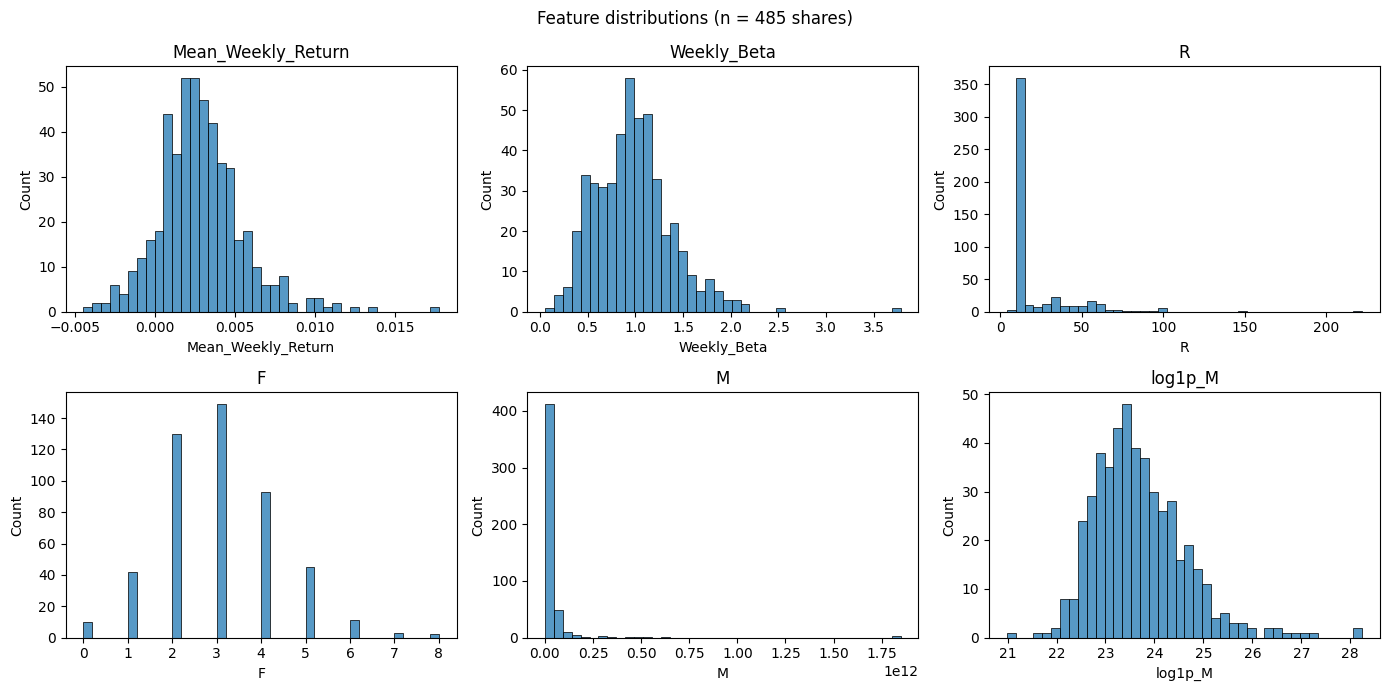

In [ ]:
plot_df = final[FEATURES].assign(log1p_M=np.log1p(final['M']))
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), ['Mean_Weekly_Return', 'Weekly_Beta', 'R', 'F', 'M', 'log1p_M']):
    sns.histplot(plot_df[col], bins=40, ax=ax); ax.set_title(col)
plt.suptitle(f'Feature distributions (n = {len(final)} shares)'); plt.tight_layout()
plt.savefig('figures/task1_feature_distributions.png', dpi=150); plt.show()

### Save and push to GitHub
Colab's working folder is deleted when the runtime resets. Run the next cell to download a zip of data/, outputs/, figures/ and requirements.txt, then commit them to your repo.

In [ ]:
with zipfile.ZipFile('task1_outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in ['data', 'outputs', 'figures']:
        for root, _, fs in os.walk(folder):
            for fn in fs: z.write(os.path.join(root, fn))
    z.write('requirements.txt')
try:
    from google.colab import files; files.download('task1_outputs.zip')
except Exception as e:
    print('Not in Colab - zip saved in working folder.', e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **TASK 2 - Stock Segmentation and Sensitivity Analysis**

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

SEED     = 42                 # random seed (reported in the report)
K_RANGE  = range(2, 9)        # feasible cluster counts required by the brief
N_INIT   = 25                 # K-means initialisations per fit
MIN_FRAC = 0.05               # helper rule: ignore k where the smallest cluster is < 5% of shares
for d in ["outputs", "figures"]:
    os.makedirs(d, exist_ok=True)

feat = pd.read_csv("outputs/feature_table.csv", index_col=0)
RR_COLS  = ["Mean_Weekly_Return", "Weekly_Beta"]
RFM_COLS = ["R", "F", "M"]
assert set(RR_COLS + RFM_COLS) <= set(feat.columns), "feature_table.csv is missing columns"
assert feat[RR_COLS + RFM_COLS].notna().all().all(), "NaN in features: Task 1 final set should have none"
print("Shares in the common set:", len(feat))
display(feat[RR_COLS + RFM_COLS].describe().T)

Shares in the common set: 485


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,485.0,2.859246e-03,2.653952e-03,-4.468092e-03,1.181088e-03,2.622775e-03,4.207596e-03,1.777248e-02
Weekly_Beta,485.0,9.748595e-01,4.069493e-01,5.545270e-02,6.666519e-01,9.531766e-01,1.179662e+00,3.778560e+00
R,485.0,2.042680e+01,2.136019e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.500000e+01,2.220000e+02
F,485.0,2.987629e+00,1.331380e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,485.0,3.945252e+10,1.292678e+11,1.297483e+09,1.017679e+10,1.670905e+10,3.236510e+10,1.847697e+12


### 2.1 Feature preparation

**Two separate feature matrices :**
- **Risk–return matrix:** Mean_Weekly_Return, Weekly_Beta
- **Trading-activity matrix:** R, F, log1p(M)


**K-means criteria checked here (the assumptions K-means relies on):**
1. numeric features on a **comparable scale** (otherwise the largest-scale feature dominates the Euclidean distance) - standardisation;
2. **outliers** pull centroids - count them, and decide whether to keep them;
3. clusters should be roughly **spherical, similar in size and variance** → inspect scatter plots;
4. **k must be chosen in advance** - compare k = 2–8 in 2.3;
5. results depend on the **random start** - fixed seed + many initialisations.

,skew,skew_after_log1p,abs_z_gt_3,iqr_rule
Mean_Weekly_Return,0.864775,NaN,6,15
Weekly_Beta,1.106043,NaN,2,10
R,3.641690,1.579975,11,113
F,0.428866,-0.925304,5,2
M,11.671923,1.076863,5,45


Rule of thumb: |skew| > 1 is strongly skewed. Outlier counts are out of 485 shares.


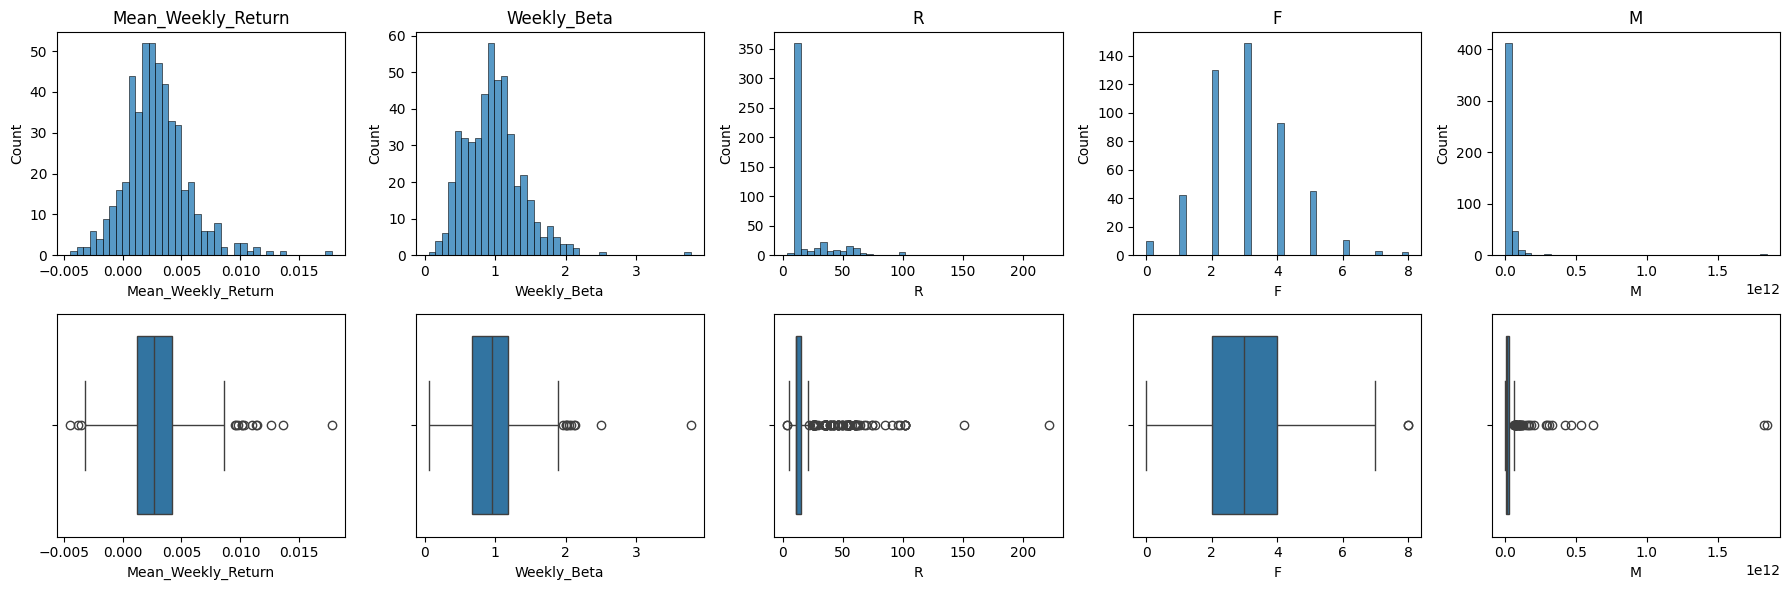

In [ ]:
# 2.1a  Two separate matrices + skew and outlier inspection
rr  = feat[RR_COLS].copy()
rfm = feat[RFM_COLS].copy()

raw_all = feat[RR_COLS + RFM_COLS]
sk = pd.DataFrame({"skew": raw_all.skew()})
sk["skew_after_log1p"] = np.nan
for c in RFM_COLS:                                   # log1p is only defined/meaningful for R, F, M (>= 0)
    sk.loc[c, "skew_after_log1p"] = np.log1p(feat[c]).skew()

def n_outliers(s):
    z = (s - s.mean()) / s.std(ddof=0)
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return pd.Series({"abs_z_gt_3": int((z.abs() > 3).sum()),
                      "iqr_rule": int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())})
out_tbl = raw_all.apply(n_outliers).T
display(sk.join(out_tbl))
print("Rule of thumb: |skew| > 1 is strongly skewed. Outlier counts are out of", len(feat), "shares.")

fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for j, c in enumerate(RR_COLS + RFM_COLS):
    sns.histplot(feat[c], bins=40, ax=axes[0, j]); axes[0, j].set_title(c)
    sns.boxplot(x=feat[c], ax=axes[1, j])
plt.tight_layout(); plt.savefig("figures/task2_1_skew_outliers.png", dpi=150); plt.show()

In [ ]:
# 2.1b  Transformations
# log1p(M) is REQUIRED by the brief. For R and F decide after reading the skew table above.
# Set True only if you can justify it (e.g. |skew| > 1 and the log makes the distribution more symmetric);
# leaving them as they are is also valid if you explain why (interpretability, F is a small count, R is already in days).
LOG_R, LOG_F = True, False

rfm_t = pd.DataFrame(index=feat.index)
rfm_t["log1p_R" if LOG_R else "R"] = np.log1p(feat["R"]) if LOG_R else feat["R"]
rfm_t["log1p_F" if LOG_F else "F"] = np.log1p(feat["F"]) if LOG_F else feat["F"]
rfm_t["log1p_M"] = np.log1p(feat["M"])

print("Skew of the trading-activity features actually used:")
display(rfm_t.skew().to_frame("skew"))

# Standardise each matrix on its own
def standardise(df):
    sc = StandardScaler()
    return pd.DataFrame(sc.fit_transform(df), index=df.index, columns=df.columns), sc

X_rr,  sc_rr  = standardise(rr)
X_rfm, sc_rfm = standardise(rfm_t)
assert X_rr.index.equals(X_rfm.index)                 # SAME shares in both matrices
print("\nStandardised means (≈0) and std (=1):")
display(pd.concat([X_rr.agg(["mean", "std"]).T, X_rfm.agg(["mean", "std"]).T]).round(3))
print("Outliers kept (|z| > 3) after standardising:",
      {"risk-return": int((X_rr.abs() > 3).any(axis=1).sum()), "trading-activity": int((X_rfm.abs() > 3).any(axis=1).sum())},
      "shares. Outliers are retained by default: they are genuine market events, but K-means is sensitive to them.")

Skew of the trading-activity features actually used:


,skew
log1p_R,1.579975
F,0.428866
log1p_M,1.076863



Standardised means (≈0) and std (=1):


,mean,std
Mean_Weekly_Return,-0.0,1.001
Weekly_Beta,0.0,1.001
log1p_R,-0.0,1.001
F,0.0,1.001
log1p_M,0.0,1.001


Outliers kept (|z| > 3) after standardising: {'risk-return': 7, 'trading-activity': 13} shares. Outliers are retained by default: they are genuine market events, but K-means is sensitive to them.


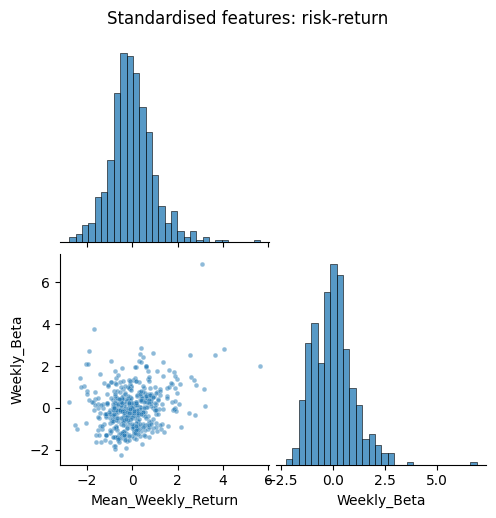

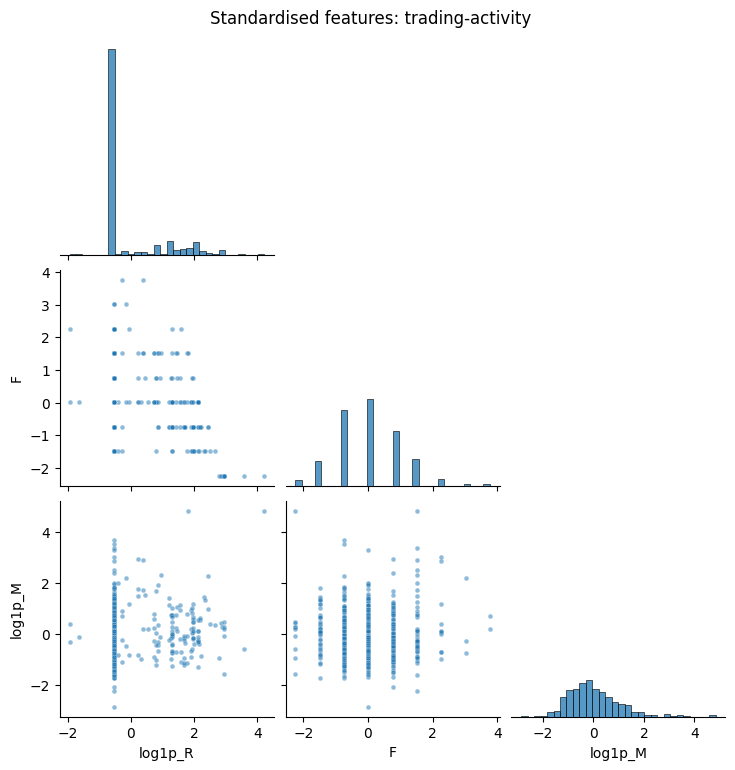

In [ ]:
# 2.1c  K-means suitability: look at the shape of the standardised data
for name, X in [("risk-return", X_rr), ("trading-activity", X_rfm)]:
    g = sns.pairplot(X, corner=True, plot_kws={"s": 12, "alpha": 0.5}, diag_kws={"bins": 30})
    g.figure.suptitle(f"Standardised features: {name}", y=1.02)
    g.figure.savefig(f"figures/task2_1_pairplot_{name.replace('-', '_')}.png", dpi=130, bbox_inches="tight")
    plt.show()

### 2.2 Agglomerative clustering (Ward)

**What it is:** bottom-up merging. Every share starts as its own cluster; at each step Ward merges the two clusters that increase the total within-cluster variance the least. It requires **Euclidean distance on standardised features**.

**Suitability:** no need to fix k in advance (the dendrogram shows the whole merge history); deterministic; works well for compact, similar-sized groups.
**Limitations:** merges are greedy and cannot be undone; sensitive to outliers; assumes roughly spherical clusters; memory/time grow quickly with the number of shares (fine for ~500).

**Choosing k:** the dendrogram alone does not give the final number of groups. We need to compare **silhouette scores, cluster sizes and interpretable profiles** for k = 2–8.

In [ ]:
# 2.2a  Ward for k = 2..8 on both matrices
def run_ward(X, ks=K_RANGE):
    rows, labs = [], {}
    for k in ks:
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X.values)   # ward => Euclidean
        sizes = np.bincount(lab)
        labs[k] = lab
        rows.append({"k": k, "silhouette": silhouette_score(X.values, lab),
                     "min_size": int(sizes.min()), "max_size": int(sizes.max()),
                     "sizes": sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index("k"), labs

def suggest_k(tbl, n, min_frac=MIN_FRAC):
    # helper only: highest silhouette among k whose smallest cluster is >= min_frac of the shares
    ok = tbl[tbl["min_size"] >= min_frac * n]
    return int((ok if len(ok) else tbl)["silhouette"].idxmax())

tbl_rr_w,  labs_rr_w  = run_ward(X_rr)
tbl_rfm_w, labs_rfm_w = run_ward(X_rfm)
print("RISK-RETURN  | Ward");      display(tbl_rr_w.round(3))
print("TRADING-ACTIVITY | Ward");  display(tbl_rfm_w.round(3))
print("Rule-based suggestion (check the profiles before accepting): RR k =", suggest_k(tbl_rr_w, len(X_rr)),
      "| RFM k =", suggest_k(tbl_rfm_w, len(X_rfm)))

RISK-RETURN  | Ward


,silhouette,min_size,max_size,sizes
k,,,,
2,0.339,92,393,"[393, 92]"
3,0.273,92,230,"[230, 163, 92]"
4,0.282,48,182,"[182, 163, 92, 48]"
5,0.304,48,182,"[182, 98, 92, 65, 48]"
6,0.320,5,182,"[182, 98, 87, 65, 48, 5]"
7,0.323,5,160,"[160, 98, 87, 65, 48, 22, 5]"
8,0.320,5,160,"[160, 98, 65, 56, 48, 31, 22, 5]"


TRADING-ACTIVITY | Ward


,silhouette,min_size,max_size,sizes
k,,,,
2,0.402,106,379,"[379, 106]"
3,0.318,73,306,"[306, 106, 73]"
4,0.325,73,183,"[183, 123, 106, 73]"
5,0.311,36,183,"[183, 123, 73, 70, 36]"
6,0.296,32,151,"[151, 123, 73, 70, 36, 32]"
7,0.289,32,151,"[151, 73, 70, 66, 57, 36, 32]"
8,0.307,14,151,"[151, 70, 66, 59, 57, 36, 32, 14]"


Rule-based suggestion (check the profiles before accepting): RR k = 2 | RFM k = 2


In [ ]:
# 2.2b  Interpretable profiles for candidate k (medians in ORIGINAL units + cluster sizes)
PROFILE_KS = (3, 4, 5)

def compact_profile(labels, cols):
    d = feat[cols].copy(); d["cluster"] = labels
    g = d.groupby("cluster")
    out = g[cols].median(); out.insert(0, "n", g.size()); return out

for k in PROFILE_KS:
    print(f" risk-return, Ward, k = {k} (medians) ");     display(compact_profile(labs_rr_w[k],  RR_COLS).round(4))
for k in PROFILE_KS:
    print(f" trading-activity, Ward, k = {k} (medians) "); display(compact_profile(labs_rfm_w[k], RFM_COLS).round(1))

 risk-return, Ward, k = 3 (medians) 


,n,Mean_Weekly_Return,Weekly_Beta
cluster,,,
0,230,0.0017,1.0384
1,92,0.0055,1.2177
2,163,0.0033,0.5808


 risk-return, Ward, k = 4 (medians) 


,n,Mean_Weekly_Return,Weekly_Beta
cluster,,,
0,163,0.0033,0.5808
1,92,0.0055,1.2177
2,182,0.0017,0.9644
3,48,0.0025,1.5139


 risk-return, Ward, k = 5 (medians) 


,n,Mean_Weekly_Return,Weekly_Beta
cluster,,,
0,92,0.0055,1.2177
1,48,0.0025,1.5139
2,182,0.0017,0.9644
3,98,0.0039,0.6663
4,65,0.0011,0.4491


... (2 outputs left out)

 trading-activity, Ward, k = 4 (medians) 


,n,R,F,M
cluster,,,,
0,106,46.5,2.0,1.948502e+10
1,183,11.0,4.0,1.185351e+10
2,73,11.0,3.0,5.634715e+10
3,123,11.0,2.0,1.724586e+10


 trading-activity, Ward, k = 5 (medians) 


,n,R,F,M
cluster,,,,
0,183,11.0,4.0,1.185351e+10
1,123,11.0,2.0,1.724586e+10
2,73,11.0,3.0,5.634715e+10
3,70,55.0,2.0,2.502932e+10
4,36,36.0,3.0,1.490924e+10


Ward k used -> risk-return: 3 | trading-activity: 4


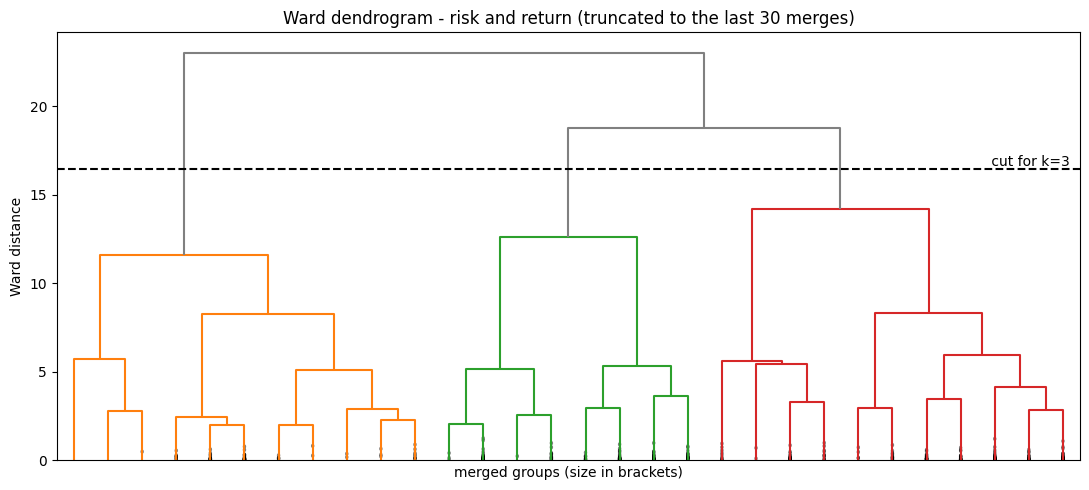

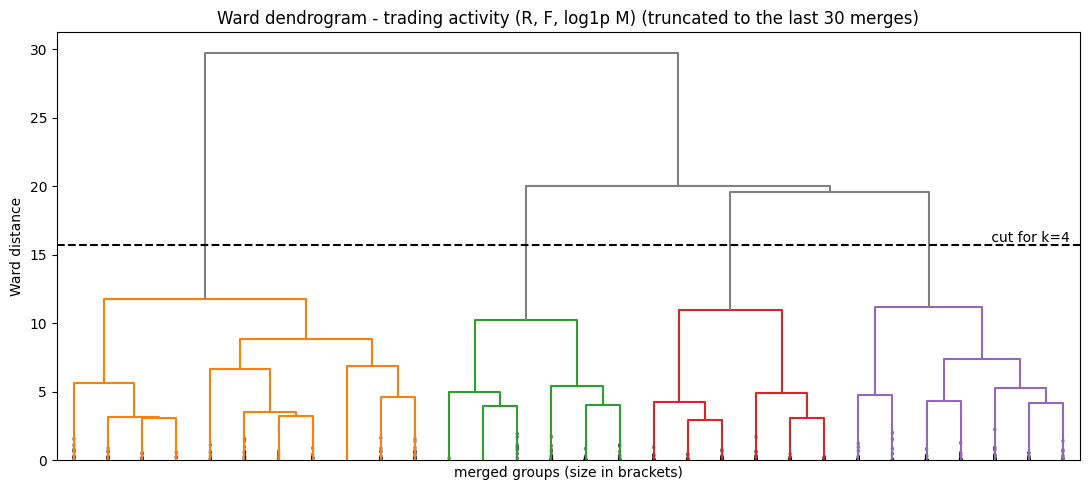

RR scipy-vs-sklearn ARI at chosen k: 1.0
RFM scipy-vs-sklearn ARI at chosen k: 1.0


In [ ]:
# 2.2c
K_RR_WARD, K_RFM_WARD = 3, 4
k_rr_ward  = K_RR_WARD  or suggest_k(tbl_rr_w,  len(X_rr))
k_rfm_ward = K_RFM_WARD or suggest_k(tbl_rfm_w, len(X_rfm))
print("Ward k used -> risk-return:", k_rr_ward, "| trading-activity:", k_rfm_ward)

def plot_dendrogram(X, k, title, fname):
    Z = linkage(X.values, method="ward", metric="euclidean")
    cut = (Z[-(k - 1), 2] + Z[-k, 2]) / 2             # height that leaves exactly k clusters
    fig, ax = plt.subplots(figsize=(11, 5))
    dendrogram(Z, truncate_mode="lastp", p=30, show_contracted=True, no_labels=True,
               color_threshold=cut, above_threshold_color="grey", ax=ax)
    ax.axhline(cut, ls="--", c="k"); ax.text(0.99, cut, f" cut for k={k}", ha="right", va="bottom", transform=ax.get_yaxis_transform())
    ax.set_title(title + " (truncated to the last 30 merges)"); ax.set_ylabel("Ward distance"); ax.set_xlabel("merged groups (size in brackets)")
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()
    return Z

Z_rr  = plot_dendrogram(X_rr,  k_rr_ward,  "Ward dendrogram - risk and return", "figures/task2_2_dendrogram_risk_return.png")
Z_rfm = plot_dendrogram(X_rfm, k_rfm_ward, "Ward dendrogram - trading activity (R, F, log1p M)", "figures/task2_2_dendrogram_trading_activity.png")

# consistency check: scipy tree cut vs sklearn labels at the chosen k (should be ~1.0)
for nm, Z, X, k, labs in [("RR", Z_rr, X_rr, k_rr_ward, labs_rr_w), ("RFM", Z_rfm, X_rfm, k_rfm_ward, labs_rfm_w)]:
    print(nm, "scipy-vs-sklearn ARI at chosen k:", round(adjusted_rand_score(fcluster(Z, k, "maxclust"), labs[k]), 4))

### 2.3 K-means clustering

**What it is:** picks k centroids, assigns each share to the nearest centroid, recomputes centroids, repeats until stable.
**Suitability:** fast, simple, easy to profile; fine with standardised numeric features.
**Limitations:** k must be chosen in advance; assumes roughly spherical, similar-sized clusters; sensitive to outliers; the result depends on the starting centroids (local optimum) - we fix random_state and use **multiple initialisations** (n_init).

**Comparing k = 2–8:** silhouette score (higher = better separated), **inertia** (within-cluster sum of squares; always falls as k grows, so look for an "elbow"), and cluster sizes.

RISK-RETURN | K-means


,inertia,silhouette,min_size,max_size,sizes
k,,,,,
2,620.681,0.387,143,342,"[342, 143]"
3,460.820,0.328,119,201,"[201, 165, 119]"
4,371.362,0.326,40,160,"[160, 153, 132, 40]"
5,309.441,0.340,27,165,"[165, 134, 109, 50, 27]"
6,265.002,0.334,5,156,"[156, 126, 105, 50, 43, 5]"
7,227.028,0.328,5,128,"[128, 103, 85, 76, 47, 41, 5]"
8,194.820,0.355,4,138,"[138, 80, 76, 75, 43, 40, 29, 4]"


TRADING-ACTIVITY | K-means


,inertia,silhouette,min_size,max_size,sizes
k,,,,,
2,997.670,0.415,102,383,"[383, 102]"
3,741.122,0.343,90,256,"[256, 139, 90]"
4,558.172,0.361,83,194,"[194, 119, 89, 83]"
5,479.873,0.348,39,141,"[141, 118, 99, 88, 39]"
6,420.337,0.344,31,139,"[139, 112, 96, 69, 38, 31]"
7,376.862,0.340,20,146,"[146, 94, 81, 68, 45, 31, 20]"
8,341.954,0.335,22,129,"[129, 69, 65, 64, 58, 42, 36, 22]"


Rule-based suggestion: RR k = 2 | RFM k = 2


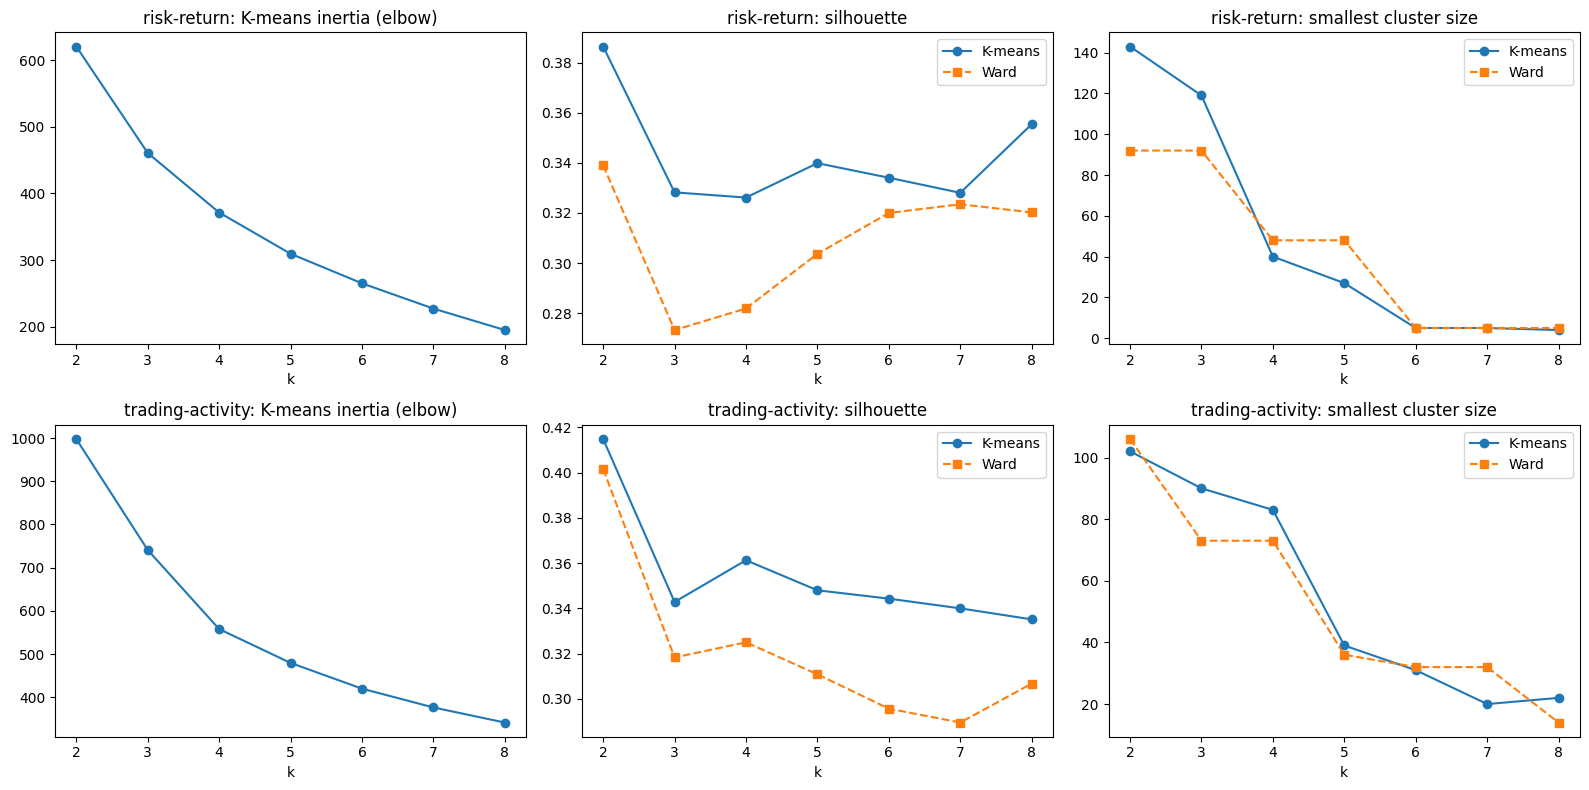

In [ ]:
# 2.3a  K-means for k = 2..8 on both matrices
def run_kmeans(X, ks=K_RANGE):
    rows, labs = [], {}
    for k in ks:
        km = KMeans(n_clusters=k, init="k-means++", n_init=N_INIT, random_state=SEED).fit(X.values)
        sizes = np.bincount(km.labels_)
        labs[k] = km.labels_
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X.values, km.labels_),
                     "min_size": int(sizes.min()), "max_size": int(sizes.max()),
                     "sizes": sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index("k"), labs

tbl_rr_k,  labs_rr_k  = run_kmeans(X_rr)
tbl_rfm_k, labs_rfm_k = run_kmeans(X_rfm)
print("RISK-RETURN | K-means");      display(tbl_rr_k.round(3))
print("TRADING-ACTIVITY | K-means"); display(tbl_rfm_k.round(3))
print("Rule-based suggestion: RR k =", suggest_k(tbl_rr_k, len(X_rr)), "| RFM k =", suggest_k(tbl_rfm_k, len(X_rfm)))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for r, (nm, tk, tw) in enumerate([("risk-return", tbl_rr_k, tbl_rr_w), ("trading-activity", tbl_rfm_k, tbl_rfm_w)]):
    axes[r, 0].plot(tk.index, tk["inertia"], "o-"); axes[r, 0].set_title(f"{nm}: K-means inertia (elbow)"); axes[r, 0].set_xlabel("k")
    axes[r, 1].plot(tk.index, tk["silhouette"], "o-", label="K-means"); axes[r, 1].plot(tw.index, tw["silhouette"], "s--", label="Ward")
    axes[r, 1].set_title(f"{nm}: silhouette"); axes[r, 1].set_xlabel("k"); axes[r, 1].legend()
    axes[r, 2].plot(tk.index, tk["min_size"], "o-", label="K-means"); axes[r, 2].plot(tw.index, tw["min_size"], "s--", label="Ward")
    axes[r, 2].set_title(f"{nm}: smallest cluster size"); axes[r, 2].set_xlabel("k"); axes[r, 2].legend()
plt.tight_layout(); plt.savefig("figures/task2_3_kmeans_selection.png", dpi=150); plt.show()

In [ ]:
# 2.3b
K_RR_KM,   K_RFM_KM   = 3, 4
k_rr_km  = K_RR_KM  or suggest_k(tbl_rr_k,  len(X_rr))
k_rfm_km = K_RFM_KM or suggest_k(tbl_rfm_k, len(X_rfm))
print("K-means k used -> risk-return:", k_rr_km, "| trading-activity:", k_rfm_km)

def init_stability(X, k, final_labels, seeds=range(10)):
    rows = []
    for s in seeds:
        km = KMeans(n_clusters=k, init="random", n_init=1, random_state=s).fit(X.values)      # ONE random start
        rows.append({"seed": s, "inertia": km.inertia_, "ARI_vs_final": adjusted_rand_score(final_labels, km.labels_)})
    return pd.DataFrame(rows)

for nm, X, k, labs in [("risk-return", X_rr, k_rr_km, labs_rr_k), ("trading-activity", X_rfm, k_rfm_km, labs_rfm_k)]:
    st = init_stability(X, k, labs[k])
    print(f"{nm}: 10 single random starts at k={k} -> inertia range {st.inertia.min():.1f}-{st.inertia.max():.1f} "
          f"(final n_init={N_INIT} fit: {tbl_rr_k.loc[k,'inertia'] if nm=='risk-return' else tbl_rfm_k.loc[k,'inertia']:.1f}); "
          f"ARI vs final: min {st.ARI_vs_final.min():.3f}, mean {st.ARI_vs_final.mean():.3f}")

K-means k used -> risk-return: 3 | trading-activity: 4
risk-return: 10 single random starts at k=3 -> inertia range 460.8-515.6 (final n_init=25 fit: 460.8); ARI vs final: min 0.251, mean 0.920
trading-activity: 10 single random starts at k=4 -> inertia range 558.2-699.1 (final n_init=25 fit: 558.2); ARI vs final: min 0.447, mean 0.888


### 2.4 Cluster profiles and algorithm comparison  

- **Profiles in original units** (mean and median of the clustering features; for M the original dollar value, not log1p).
- **Labelled 2D visualisation:** the risk–return matrix already has 2 features, so it is plotted directly (standardised axes = the space the algorithms used). The trading-activity matrix has 3, so **PCA** projects it to 2 dimensions; axis labels show the share of variance each component keeps, and the loadings explains what the axes mean. PCA is for **display only** — clustering was done on the full standardised matrix.
- **Algorithm comparison on the same shares:** cross-tabulation and the adjusted Rand index (ARI; 1 = identical partitions, ≈0 = chance; unaffected by arbitrary cluster numbers).

Cluster numbers are arbitrary, so clusters are **relabelled** 1…k in ascending order of mean beta (risk-return) or mean M (trading activity) to make tables readable.

In [ ]:
# 2.4a  Final four solutions (same shares), consistently labelled
def relabel(labels, key):
    order = pd.Series(np.asarray(key)).groupby(np.asarray(labels)).mean().sort_values().index
    mp = {old: new for new, old in enumerate(order, start=1)}
    return np.array([mp[l] for l in labels])

sol = {
    "RR_Ward":   relabel(labs_rr_w[k_rr_ward],   feat["Weekly_Beta"]),
    "RR_KMeans": relabel(labs_rr_k[k_rr_km],     feat["Weekly_Beta"]),
    "RFM_Ward":  relabel(labs_rfm_w[k_rfm_ward], feat["M"]),
    "RFM_KMeans":relabel(labs_rfm_k[k_rfm_km],   feat["M"]),
}
assign = feat.copy()
for k_, v in sol.items():
    assign[k_] = v
assign.to_csv("outputs/cluster_assignments.csv")
print({k_: int(len(set(v))) for k_, v in sol.items()}, "clusters | shares:", len(assign))

def profile_orig(key, cols):
    g = assign.groupby(key)[cols]
    out = pd.concat({"mean": g.mean(), "median": g.median()}, axis=1)
    out.insert(0, "n", assign.groupby(key).size()); out.insert(1, "pct", (100 * assign.groupby(key).size() / len(assign)).round(1))
    return out

for key, cols in [("RR_Ward", RR_COLS), ("RR_KMeans", RR_COLS), ("RFM_Ward", RFM_COLS), ("RFM_KMeans", RFM_COLS)]:
    print(f"=== {key}: profile in ORIGINAL units ===")
    display(profile_orig(key, cols).round(4 if key.startswith("RR") else 1))

{'RR_Ward': 3, 'RR_KMeans': 3, 'RFM_Ward': 4, 'RFM_KMeans': 4} clusters | shares: 485
=== RR_Ward: profile in ORIGINAL units ===


/tmp/ipykernel_394/2522389677.py:22: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  out.insert(0, "n", assign.groupby(key).size()); out.insert(1, "pct", (100 * assign.groupby(key).size() / len(assign)).round(1))
/tmp/ipykernel_394/2522389677.py:22: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  out.insert(0, "n", assign.groupby(key).size()); out.insert(1, "pct", (100 * assign.groupby(key).size() / len(assign)).round(1))


n   pct               mean                         median            
                   Mean_Weekly_Return Weekly_Beta Mean_Weekly_Return Weekly_Beta
RR_Ward                                                                         
1        163  33.6             0.0029      0.6024             0.0033      0.5808
2        230  47.4             0.0015      1.1096             0.0017      1.0384
3         92  19.0             0.0063      1.2981             0.0055      1.2177

=== RR_KMeans: profile in ORIGINAL units ===


/tmp/ipykernel_394/2522389677.py:22: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  out.insert(0, "n", assign.groupby(key).size()); out.insert(1, "pct", (100 * assign.groupby(key).size() / len(assign)).round(1))
/tmp/ipykernel_394/2522389677.py:22: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  out.insert(0, "n", assign.groupby(key).size()); out.insert(1, "pct", (100 * assign.groupby(key).size() / len(assign)).round(1))


n   pct               mean                         median            
                     Mean_Weekly_Return Weekly_Beta Mean_Weekly_Return Weekly_Beta
RR_KMeans                                                                         
1          201  41.4             0.0026      0.6319             0.0026      0.6220
2          165  34.0             0.0009      1.1391             0.0012      1.0805
3          119  24.5             0.0060      1.3264             0.0053      1.2214

... (2 outputs left out)

n   pct  mean                    median                   
                        R    F             M      R    F             M
RFM_Ward                                                              
1         183  37.7  11.2  3.8  1.286347e+10   11.0  4.0  1.185351e+10
2         123  25.4  11.0  1.8  2.547996e+10   11.0  2.0  1.724586e+10
3         106  21.9  52.4  2.4  4.203975e+10   46.5  2.0  1.948502e+10
4          73  15.1  13.0  3.7  1.258932e+11   11.0  3.0  5.634715e+10

=== RFM_KMeans: profile in ORIGINAL units ===


/tmp/ipykernel_394/2522389677.py:22: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  out.insert(0, "n", assign.groupby(key).size()); out.insert(1, "pct", (100 * assign.groupby(key).size() / len(assign)).round(1))
/tmp/ipykernel_394/2522389677.py:22: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  out.insert(0, "n", assign.groupby(key).size()); out.insert(1, "pct", (100 * assign.groupby(key).size() / len(assign)).round(1))


n   pct  mean                    median                   
                          R    F             M      R    F             M
RFM_KMeans                                                              
1           119  24.5  13.4  4.6  1.478568e+10   11.0  4.0  1.269634e+10
2           194  40.0  11.3  2.4  1.500737e+10   11.0  2.0  1.310477e+10
3            89  18.4  56.6  2.0  4.710065e+10   54.0  2.0  2.124212e+10
4            83  17.1  13.0  3.3  1.237540e+11   11.0  3.0  6.324942e+10

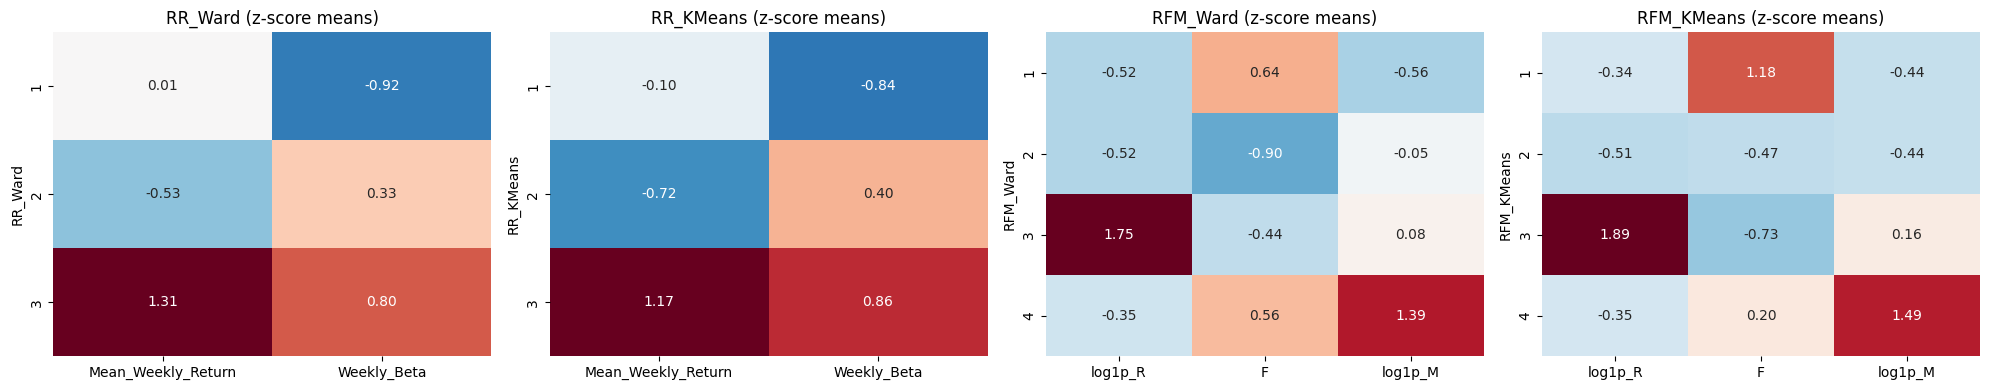

In [ ]:
# 2.4b  Standardised cluster means (heatmaps: which features define each cluster?) ----
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (key, X) in zip(axes, [("RR_Ward", X_rr), ("RR_KMeans", X_rr), ("RFM_Ward", X_rfm), ("RFM_KMeans", X_rfm)]):
    z = X.groupby(assign[key]).mean()
    sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar=False); ax.set_title(key + " (z-score means)")
plt.tight_layout(); plt.savefig("figures/task2_4_zscore_heatmaps.png", dpi=150); plt.show()

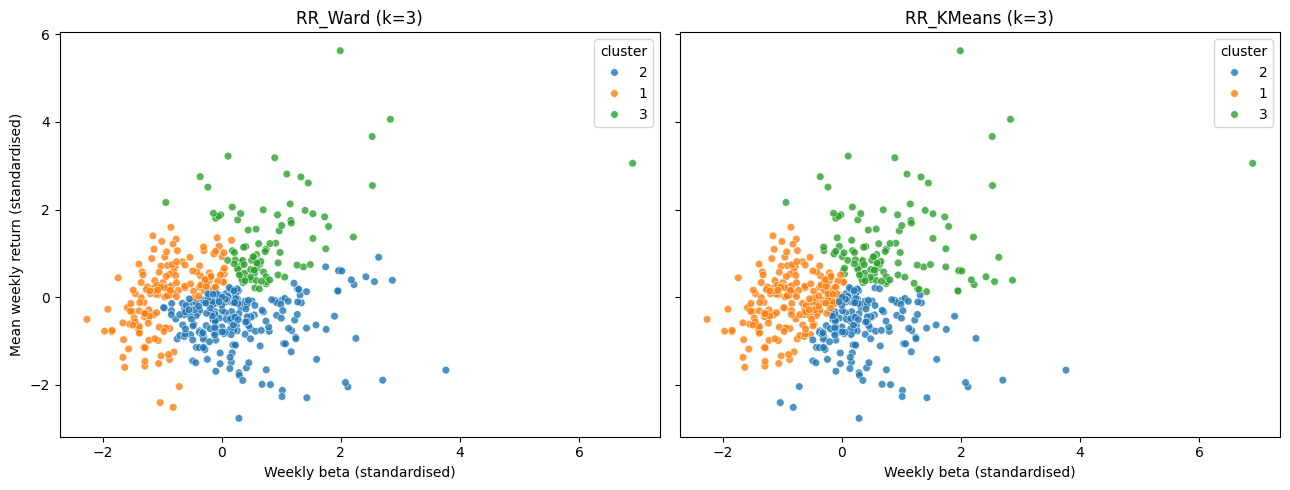

PCA explained variance: PC1 43.6%, PC2 33.7%, total 77.2%


,PC1,PC2
log1p_R,0.712,0.028
F,-0.649,0.405
log1p_M,0.266,0.914


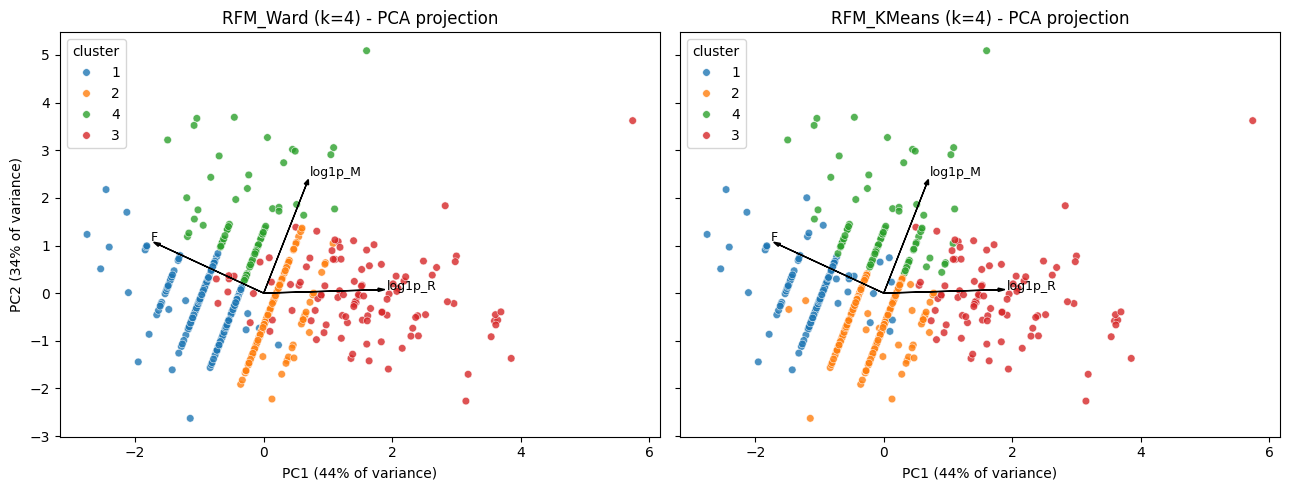

In [ ]:
# 2.4c  Labelled 2D visualisations
# Risk-return: 2 features -> plotted directly (standardised axes)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, key in zip(axes, ["RR_Ward", "RR_KMeans"]):
    sns.scatterplot(x=X_rr["Weekly_Beta"], y=X_rr["Mean_Weekly_Return"], hue=assign[key].astype(str),
                    palette="tab10", s=30, alpha=0.8, ax=ax)
    ax.set_title(f"{key} (k={assign[key].nunique()})"); ax.set_xlabel("Weekly beta (standardised)"); ax.set_ylabel("Mean weekly return (standardised)")
    ax.legend(title="cluster")
plt.tight_layout(); plt.savefig("figures/task2_4_scatter_risk_return.png", dpi=150); plt.show()

# Trading activity: 3 features -> PCA to 2D (display only)
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm.values)
P = pca.transform(X_rfm.values)
ev = pca.explained_variance_ratio_
print("PCA explained variance: PC1 {:.1%}, PC2 {:.1%}, total {:.1%}".format(ev[0], ev[1], ev.sum()))
load = pd.DataFrame(pca.components_.T, index=X_rfm.columns, columns=["PC1", "PC2"])
display(load.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, key in zip(axes, ["RFM_Ward", "RFM_KMeans"]):
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=assign[key].astype(str), palette="tab10", s=30, alpha=0.8, ax=ax)
    for f_ in load.index:                                           # loading arrows
        ax.arrow(0, 0, load.loc[f_, "PC1"] * 2.5, load.loc[f_, "PC2"] * 2.5, color="k", head_width=0.07)
        ax.text(load.loc[f_, "PC1"] * 2.7, load.loc[f_, "PC2"] * 2.7, f_, fontsize=9)
    ax.set_title(f"{key} (k={assign[key].nunique()}) - PCA projection")
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)"); ax.legend(title="cluster")
plt.tight_layout(); plt.savefig("figures/task2_4_pca_trading_activity.png", dpi=150); plt.show()

In [ ]:
# 2.4d  Ward vs K-means on the SAME shares
for nm, a, b, X in [("risk-return", "RR_Ward", "RR_KMeans", X_rr), ("trading-activity", "RFM_Ward", "RFM_KMeans", X_rfm)]:
    print(f"{nm}: Ward (rows) vs K-means (columns) ")
    display(pd.crosstab(assign[a], assign[b], margins=True))
    print("Adjusted Rand index:", round(adjusted_rand_score(assign[a], assign[b]), 3),
          "| silhouette Ward:", round(silhouette_score(X.values, assign[a]), 3),
          "| silhouette K-means:", round(silhouette_score(X.values, assign[b]), 3), "\n")

risk-return: Ward (rows) vs K-means (columns) 


RR_KMeans,1,2,3,All
RR_Ward,,,,
1,147,3,13,163
2,54,160,16,230
3,0,2,90,92
All,201,165,119,485


Adjusted Rand index: 0.516 | silhouette Ward: 0.273 | silhouette K-means: 0.328 

trading-activity: Ward (rows) vs K-means (columns) 


RFM_KMeans,1,2,3,4,All
RFM_Ward,,,,,
1,102,80,0,1,183
2,0,103,0,20,123
3,13,2,89,2,106
4,4,9,0,60,73
All,119,194,89,83,485


Adjusted Rand index: 0.443 | silhouette Ward: 0.325 | silhouette K-means: 0.361 



### 2.5 RFM sensitivity and correlated inputs

#### 2.5.1 Correlation analysis
Correlations among **R, F and log1p(M)** (the features actually clustered). If two features move together, standardising each to variance 1 does **not** remove the overlap: the shared activity signal enters the Euclidean distance more than once, so trading activity gets extra influence. But **correlation alone does not prove a feature dominates** — we also check how much of each feature's variance the clusters actually explain (η², between-cluster share of total variance).

### 2.5.2 Removal of Monetary `[3]`
Repeating the selected Ward trading-activity solution with **R and F only**: same shares, same k, a **freshly standardised** reduced matrix. Compare memberships with the **adjusted Rand index** and compare the clusters' **traded value (M) profiles**. Traded value is only a **liquidity proxy** (no spread or price impact is measured).

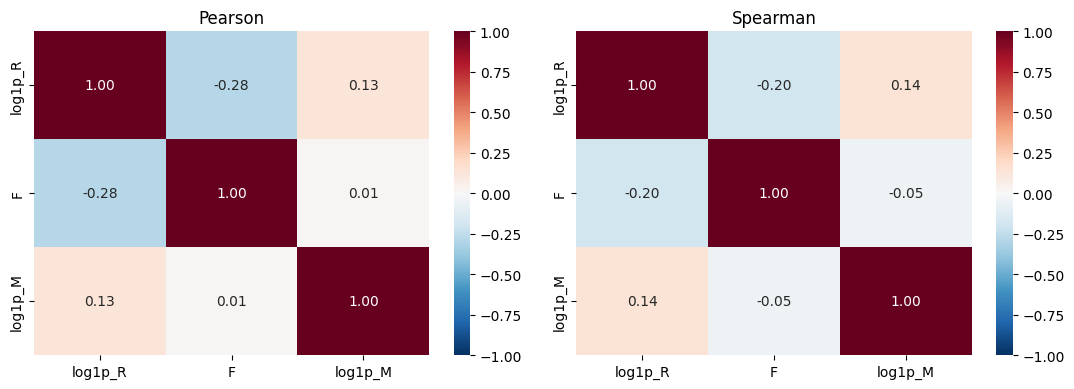

PCA explained variance ratio of the standardised RFM matrix: [0.436 0.337 0.228]
(with 3 uncorrelated standardised features each component would be ~0.333)
Share of each feature's variance explained by the clusters (eta squared):


,RFM_Ward,RFM_KMeans
log1p_R,0.858,0.806
F,0.446,0.535
log1p_M,0.415,0.508


In [ ]:
# 2.5.1  Correlations among R, F, log1p(M)
corr_p = rfm_t.corr(method="pearson"); corr_s = rfm_t.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(corr_p, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0]); axes[0].set_title("Pearson")
sns.heatmap(corr_s, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title("Spearman")
plt.tight_layout(); plt.savefig("figures/task2_5_correlations.png", dpi=150); plt.show()

# How much of the standardised variance sits on one shared dimension? (PC1 share of the 3-feature matrix)
pca_full = PCA(random_state=SEED).fit(X_rfm.values)
print("PCA explained variance ratio of the standardised RFM matrix:", pca_full.explained_variance_ratio_.round(3))
print("(with 3 uncorrelated standardised features each component would be ~0.333)")

# Correlation is not proof of dominance: how much of each feature's variance do the clusters explain?
def eta_squared(X, labels):
    labels = np.asarray(labels); out = {}
    for c in X.columns:
        x = X[c].values; tot = ((x - x.mean()) ** 2).sum()
        bet = sum((labels == g).sum() * (x[labels == g].mean() - x.mean()) ** 2 for g in np.unique(labels))
        out[c] = bet / tot
    return pd.Series(out)

eta = pd.DataFrame({"RFM_Ward": eta_squared(X_rfm, assign["RFM_Ward"]), "RFM_KMeans": eta_squared(X_rfm, assign["RFM_KMeans"])})
print("Share of each feature's variance explained by the clusters (eta squared):"); display(eta.round(3))

k = 4 | Adjusted Rand index (RFM Ward vs R,F-only Ward): 0.668
Silhouette (own feature space): RFM 0.325 | R,F only 0.519

Membership cross-tab (rows = full RFM Ward, columns = R,F-only Ward):


RF_only_Ward,1,2,3,4,All
RFM_Ward,,,,,
1,183,0,0,0,183
2,0,123,0,0,123
3,5,0,57,44,106
4,63,2,0,8,73
All,251,125,57,52,485



Traded value (M) by cluster - FULL RFM Ward:


,n,median_M_USD_bn,mean_M_USD_bn,min_M_USD_bn,max_M_USD_bn
RFM_Ward,,,,,
1,183,11.85,12.86,1.30,37.90
2,123,17.25,25.48,3.69,109.01
3,106,19.49,42.04,4.37,1825.34
4,73,56.35,125.89,25.52,1847.70


Traded value (M) by cluster - R,F-ONLY Ward:


,n,median_M_USD_bn,mean_M_USD_bn,min_M_USD_bn,max_M_USD_bn
RF_only_Ward,,,,,
1,251,14.74,30.06,1.30,468.18
2,125,17.70,34.34,3.69,623.30
3,57,21.24,58.52,4.37,1825.34
4,52,18.54,76.17,5.90,1847.70


Share of log1p(M) variance explained by the clusters (eta squared):


,eta2
RFM Ward (with M),0.415
"R,F-only Ward (M not used)",0.021


R,F-only eta2 for R and F themselves:


,eta2
log1p_R,0.878
F,0.608


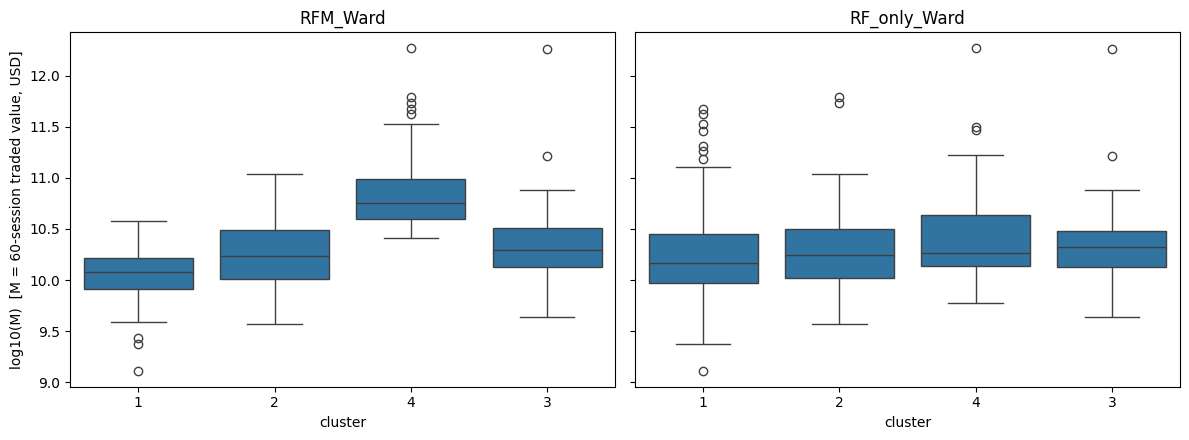

In [ ]:
# 2.5.2  Ward on R and F only (M removed)
rf_cols = [c for c in rfm_t.columns if c != "log1p_M"]
X_rf, sc_rf = standardise(rfm_t[rf_cols])                 # fresh scaler on the reduced matrix
assert X_rf.index.equals(X_rfm.index)                     # same shares
lab_rf = relabel(AgglomerativeClustering(n_clusters=k_rfm_ward, linkage="ward").fit_predict(X_rf.values), feat["M"])
assign["RF_only_Ward"] = lab_rf
assign.to_csv("outputs/cluster_assignments.csv")

ari = adjusted_rand_score(assign["RFM_Ward"], assign["RF_only_Ward"])
print(f"k = {k_rfm_ward} | Adjusted Rand index (RFM Ward vs R,F-only Ward): {ari:.3f}")
print("Silhouette (own feature space): RFM", round(silhouette_score(X_rfm.values, assign['RFM_Ward']), 3),
      "| R,F only", round(silhouette_score(X_rf.values, lab_rf), 3))
print("\nMembership cross-tab (rows = full RFM Ward, columns = R,F-only Ward):")
display(pd.crosstab(assign["RFM_Ward"], assign["RF_only_Ward"], margins=True))

# Traded value (M, USD) profile of each solution's clusters
def m_profile(key):
    g = assign.groupby(key)["M"]
    out = pd.DataFrame({"n": g.size(), "median_M_USD_bn": g.median() / 1e9, "mean_M_USD_bn": g.mean() / 1e9,
                        "min_M_USD_bn": g.min() / 1e9, "max_M_USD_bn": g.max() / 1e9})
    return out
print("\nTraded value (M) by cluster - FULL RFM Ward:");  display(m_profile("RFM_Ward").round(2))
print("Traded value (M) by cluster - R,F-ONLY Ward:");   display(m_profile("RF_only_Ward").round(2))

# Does M mainly separate liquidity levels? Compare how much log1p(M) variance each partition explains
eta_m = pd.Series({"RFM Ward (with M)": eta_squared(X_rfm[["log1p_M"]], assign["RFM_Ward"])["log1p_M"],
                   "R,F-only Ward (M not used)": eta_squared(X_rfm[["log1p_M"]], assign["RF_only_Ward"])["log1p_M"]})
print("Share of log1p(M) variance explained by the clusters (eta squared):"); display(eta_m.round(3).to_frame("eta2"))
print("R,F-only eta2 for R and F themselves:"); display(eta_squared(X_rf, assign["RF_only_Ward"]).round(3).to_frame("eta2"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, key in zip(axes, ["RFM_Ward", "RF_only_Ward"]):
    sns.boxplot(x=assign[key].astype(str), y=np.log10(assign["M"]), ax=ax)
    ax.set_title(key); ax.set_xlabel("cluster"); ax.set_ylabel("log10(M)  [M = 60-session traded value, USD]")
plt.tight_layout(); plt.savefig("figures/task2_5_M_by_cluster.png", dpi=150); plt.show()

In [ ]:
for k in (3, 4):
    print(f"RR K-means k={k}");  display(compact_profile(labs_rr_k[k],  RR_COLS).round(4))
    print(f"RFM K-means k={k}"); display(compact_profile(labs_rfm_k[k], RFM_COLS).round(1))

RR K-means k=3


,n,Mean_Weekly_Return,Weekly_Beta
cluster,,,
0,165,0.0012,1.0805
1,201,0.0026,0.6220
2,119,0.0053,1.2214


RFM K-means k=3


,n,R,F,M
cluster,,,,
0,139,11.0,3.0,4.289160e+10
1,90,53.5,2.0,2.118345e+10
2,256,11.0,3.0,1.117761e+10


RR K-means k=4


,n,Mean_Weekly_Return,Weekly_Beta
cluster,,,
0,132,0.0011,1.1418
1,153,0.0019,0.5788
2,40,0.0070,1.6809
3,160,0.0043,0.9851


RFM K-means k=4


,n,R,F,M
cluster,,,,
0,194,11.0,2.0,1.310477e+10
1,83,11.0,3.0,6.324942e+10
2,119,11.0,4.0,1.269634e+10
3,89,54.0,2.0,2.124212e+10


In [ ]:
# Save the selection tables (evidence for the report) and zip outputs
tbl_rr_w.to_csv("outputs/k_selection_RR_Ward.csv"); tbl_rfm_w.to_csv("outputs/k_selection_RFM_Ward.csv")
tbl_rr_k.to_csv("outputs/k_selection_RR_KMeans.csv"); tbl_rfm_k.to_csv("outputs/k_selection_RFM_KMeans.csv")

import zipfile
with zipfile.ZipFile("task2_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["outputs", "figures"]:
        for root, _, fs in os.walk(folder):
            for fn in fs: z.write(os.path.join(root, fn))
try:
    from google.colab import files; files.download("task2_outputs.zip")
except Exception as e:
    print("Not in Colab - zip saved in the working folder.", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>